# L5. Informed Search Strategies - PacMan World

Heuristic search plays a significant role in game AI. It uses rules of thumb, or heuristic functions, to efficiently navigate vast game state spaces and find optimal or near-optimal moves, outperforming brute-force methods.

PAC-MAN is one of the most popular game which also can be used as environment to test the "level of intelegence" of Problem-Solving Agents.

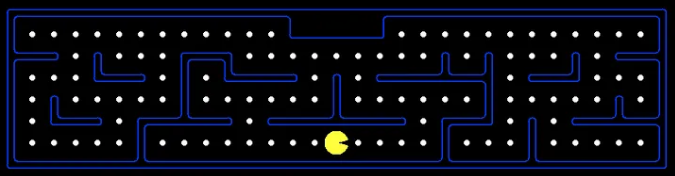

**Goal**: Help Pac-man Agent find its way through the maze. The Agent is required to visit every food pellet at least once on oits way to the exit.

**Techniques**: Heuristic Search - A*

## A* Search

The A* algorithm's efficiency comes from its smart evaluation of paths using three key components: **g(n), h(n)**, and **f(n)**. These components work together to guide the search process toward the most promising paths.

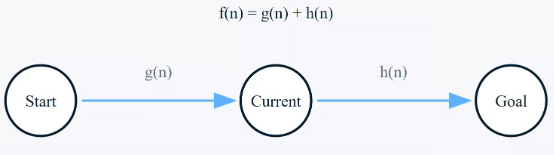

* **g(n)** = sum of edge costs from start to n

* heuristic function **h(n)** = estimate of lowest cost path from n to goal

### The heuristic 

In our example the **Euclidean distance** is used as a heuristic.

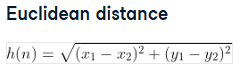



Let’s take a look at a quick graphic to help illustrate this.

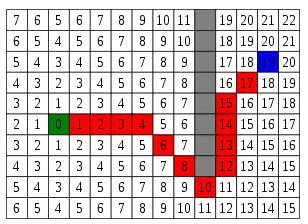

Let’s say node(0) is our starting position and node(19) is our end position. Let’s also say that our current node is at the the red square node(4).

So let’s calculate the distance. 

If we take a look we’ll see that if we go over 7 spaces and up 3 spaces, we’ve reached our end node (node(19)).

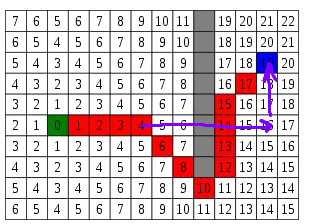

a² + b² = c². After we’ve applied this, we’ll see that currentNode.h = 7² + 3². Or currentNode.h = sqrt(58).


## Maze & State Space

Pacman World is a case of maze.

Mazes are a classic example of a state-space search problem in AI. 

* **State**: Each position in the maze (e.g., a specific grid cell) represents a state.
* **Actions**: The ***possible*** moves an agent can make from a given state, such as moving *up, down, left*, or *right*.
* **Goal**: The state where the agent needs to arrive, such as the maze's exit or the cell with a treasure.

       

### Maze generator

To generate a maze in this assignmenr you can use our simple Maze generator (from prev. Lab) as a base, and then customise it to get a PacMan World.

The `maze` can be represented as a `2D array`, where:
* 0 represents a wall , 
* and 1 represents an open path,
* 2 represents food

In [1]:
n=10

In [4]:
from src.mazeData import makeMaze

In [6]:
maze1=makeMaze(n)
maze1

array([[1, 1, 1, 0, 1, 1, 0, 1, 1, 1],
       [1, 1, 0, 1, 1, 1, 1, 1, 2, 1],
       [1, 2, 1, 0, 1, 1, 1, 2, 1, 1],
       [1, 0, 1, 1, 1, 0, 2, 1, 1, 1],
       [1, 1, 0, 1, 1, 0, 1, 1, 1, 1],
       [0, 0, 1, 1, 2, 1, 1, 1, 1, 1],
       [1, 0, 0, 0, 1, 1, 1, 1, 1, 1],
       [1, 1, 1, 0, 2, 1, 2, 1, 0, 1],
       [1, 2, 1, 1, 1, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 0, 1, 0, 2, 1, 1]])

Let's visualize our Maze as a Grid with Seaborn:
* a pink cell represent an initial state
* a green cell - a goal
* a dark blue cell - a wall
* an orange cell - food

In [7]:
from src.mazeData import draw_maze

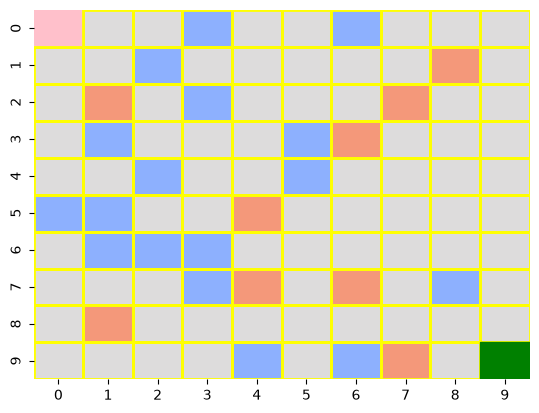

In [11]:
draw_maze(maze1)

Now we need to define AVAILABLE actions.

In [12]:
from src.mazeData import defineMazeAvailableActions

In [13]:
mazeAvalActs=defineMazeAvailableActions(maze1)
mazeAvalActs

{(0, 0): ['right', 'down'],
 (0, 1): ['left', 'right', 'down'],
 (0, 2): ['left'],
 (0, 3): [],
 (0, 4): ['right', 'down'],
 (0, 5): ['left', 'down'],
 (0, 6): [],
 (0, 7): ['right', 'down'],
 (0, 8): ['left', 'right', 'down'],
 (0, 9): ['left', 'down'],
 (1, 0): ['up', 'right', 'down'],
 (1, 1): ['left', 'up', 'down'],
 (1, 2): [],
 (1, 3): ['right'],
 (1, 4): ['left', 'up', 'right', 'down'],
 (1, 5): ['left', 'up', 'right', 'down'],
 (1, 6): ['left', 'right', 'down'],
 (1, 7): ['left', 'up', 'right', 'down'],
 (1, 8): ['left', 'up', 'right', 'down'],
 (1, 9): ['left', 'up', 'down'],
 (2, 0): ['up', 'right', 'down'],
 (2, 1): ['left', 'up', 'right'],
 (2, 2): ['left', 'down'],
 (2, 3): [],
 (2, 4): ['up', 'right', 'down'],
 (2, 5): ['left', 'up', 'right'],
 (2, 6): ['left', 'up', 'right', 'down'],
 (2, 7): ['left', 'up', 'right', 'down'],
 (2, 8): ['left', 'up', 'right', 'down'],
 (2, 9): ['left', 'up', 'down'],
 (3, 0): ['up', 'down'],
 (3, 1): [],
 (3, 2): ['up', 'right'],
 (3, 3): 

In [ ]:
mazeAvalActs[(7,4)] # correct: food is there, but it is possible to move U,R,D from it (not L due to wall at (7,3))

['up', 'right', 'down']

In [ ]:
maze1[7,4] # 2- food

np.int64(2)

Next we need to define the **Transition (Transformation) Model (TM)**

Transition Model: Describes what each action does. RESULT(s, a) returns the state that results from performing action "a" in state "s".

In [17]:
from src.mazeData import makeMazeTransformationModel

Since the TM describes what each action does the set of available actions is used as a input for it.

In [18]:
maze1TM=makeMazeTransformationModel(mazeAvalActs)
maze1TM

{(0, 0): {'right': (0, 1), 'down': (1, 0)},
 (0, 1): {'left': (0, 0), 'right': (0, 2), 'down': (1, 1)},
 (0, 2): {'left': (0, 1)},
 (0, 3): {},
 (0, 4): {'right': (0, 5), 'down': (1, 4)},
 (0, 5): {'left': (0, 4), 'down': (1, 5)},
 (0, 6): {},
 (0, 7): {'right': (0, 8), 'down': (1, 7)},
 (0, 8): {'left': (0, 7), 'right': (0, 9), 'down': (1, 8)},
 (0, 9): {'left': (0, 8), 'down': (1, 9)},
 (1, 0): {'up': (0, 0), 'right': (1, 1), 'down': (2, 0)},
 (1, 1): {'left': (1, 0), 'up': (0, 1), 'down': (2, 1)},
 (1, 2): {},
 (1, 3): {'right': (1, 4)},
 (1, 4): {'left': (1, 3), 'up': (0, 4), 'right': (1, 5), 'down': (2, 4)},
 (1, 5): {'left': (1, 4), 'up': (0, 5), 'right': (1, 6), 'down': (2, 5)},
 (1, 6): {'left': (1, 5), 'right': (1, 7), 'down': (2, 6)},
 (1, 7): {'left': (1, 6), 'up': (0, 7), 'right': (1, 8), 'down': (2, 7)},
 (1, 8): {'left': (1, 7), 'up': (0, 8), 'right': (1, 9), 'down': (2, 8)},
 (1, 9): {'left': (1, 8), 'up': (0, 9), 'down': (2, 9)},
 (2, 0): {'up': (1, 0), 'right': (2, 1),

The data above is our graph data to build the `MazeGraph`

### Maze Graph

In [19]:
from src.graphProblemClass import GraphProblem

Based on this dictionary we need to build a graph

However, we need to create the derived class - `mazeGraph`

In [20]:
from src.maze2025GraphClass import mazeGraph

In [21]:
mazeWorldGraph1 = mazeGraph(maze1TM)

In [22]:
mazeWorldGraph1.graph_dict

{(0, 0): {(0, 1): 0, (1, 0): 1},
 (0, 1): {(0, 0): 0, (0, 2): 0, (1, 1): 1},
 (0, 2): {(0, 1): 0},
 (0, 4): {(0, 5): 0, (1, 4): 1},
 (0, 5): {(0, 4): 0, (1, 5): 1},
 (0, 7): {(0, 8): 0, (1, 7): 1},
 (0, 8): {(0, 7): 0, (0, 9): 0, (1, 8): 1},
 (0, 9): {(0, 8): 0, (1, 9): 1},
 (1, 0): {(0, 0): 2, (1, 1): 0, (2, 0): 1},
 (1, 1): {(1, 0): 0, (0, 1): 2, (2, 1): 1},
 (1, 3): {(1, 4): 0},
 (1, 4): {(1, 3): 0, (0, 4): 2, (1, 5): 0, (2, 4): 1},
 (1, 5): {(1, 4): 0, (0, 5): 2, (1, 6): 0, (2, 5): 1},
 (1, 6): {(1, 5): 0, (1, 7): 0, (2, 6): 1},
 (1, 7): {(1, 6): 0, (0, 7): 2, (1, 8): 0, (2, 7): 1},
 (1, 8): {(1, 7): 0, (0, 8): 2, (1, 9): 0, (2, 8): 1},
 (1, 9): {(1, 8): 0, (0, 9): 2, (2, 9): 1},
 (2, 0): {(1, 0): 2, (2, 1): 0, (3, 0): 1},
 (2, 1): {(2, 0): 0, (1, 1): 2, (2, 2): 0},
 (2, 2): {(2, 1): 0, (3, 2): 1},
 (2, 4): {(1, 4): 2, (2, 5): 0, (3, 4): 1},
 (2, 5): {(2, 4): 0, (1, 5): 2, (2, 6): 0},
 (2, 6): {(2, 5): 0, (1, 6): 2, (2, 7): 0, (3, 6): 1},
 (2, 7): {(2, 6): 0, (1, 7): 2, (2, 8): 0, 

In [23]:
mazeWorldGraph1.get((0,0))

{(0, 1): 0, (1, 0): 1}

In [24]:
from src.mazeData import mazeStatesLocations

In [25]:
list(maze1TM.keys())

[(0, 0),
 (0, 1),
 (0, 2),
 (0, 3),
 (0, 4),
 (0, 5),
 (0, 6),
 (0, 7),
 (0, 8),
 (0, 9),
 (1, 0),
 (1, 1),
 (1, 2),
 (1, 3),
 (1, 4),
 (1, 5),
 (1, 6),
 (1, 7),
 (1, 8),
 (1, 9),
 (2, 0),
 (2, 1),
 (2, 2),
 (2, 3),
 (2, 4),
 (2, 5),
 (2, 6),
 (2, 7),
 (2, 8),
 (2, 9),
 (3, 0),
 (3, 1),
 (3, 2),
 (3, 3),
 (3, 4),
 (3, 5),
 (3, 6),
 (3, 7),
 (3, 8),
 (3, 9),
 (4, 0),
 (4, 1),
 (4, 2),
 (4, 3),
 (4, 4),
 (4, 5),
 (4, 6),
 (4, 7),
 (4, 8),
 (4, 9),
 (5, 0),
 (5, 1),
 (5, 2),
 (5, 3),
 (5, 4),
 (5, 5),
 (5, 6),
 (5, 7),
 (5, 8),
 (5, 9),
 (6, 0),
 (6, 1),
 (6, 2),
 (6, 3),
 (6, 4),
 (6, 5),
 (6, 6),
 (6, 7),
 (6, 8),
 (6, 9),
 (7, 0),
 (7, 1),
 (7, 2),
 (7, 3),
 (7, 4),
 (7, 5),
 (7, 6),
 (7, 7),
 (7, 8),
 (7, 9),
 (8, 0),
 (8, 1),
 (8, 2),
 (8, 3),
 (8, 4),
 (8, 5),
 (8, 6),
 (8, 7),
 (8, 8),
 (8, 9),
 (9, 0),
 (9, 1),
 (9, 2),
 (9, 3),
 (9, 4),
 (9, 5),
 (9, 6),
 (9, 7),
 (9, 8),
 (9, 9)]

In [26]:
mazeWorldGraph2 = mazeGraph(maze1TM, mazeStatesLocations(list(maze1TM.keys())))

In [27]:
mazeWorldGraph2.nodes()[:5]

[(4, 0), (4, 9), (8, 0), (8, 9), (9, 8)]

In [28]:
mazeWorldGraph2.locations

{(0, 0): (0, 0),
 (0, 1): (100, 0),
 (0, 2): (200, 0),
 (0, 3): (300, 0),
 (0, 4): (400, 0),
 (0, 5): (500, 0),
 (0, 6): (600, 0),
 (0, 7): (700, 0),
 (0, 8): (800, 0),
 (0, 9): (900, 0),
 (1, 0): (0, 100),
 (1, 1): (100, 100),
 (1, 2): (200, 100),
 (1, 3): (300, 100),
 (1, 4): (400, 100),
 (1, 5): (500, 100),
 (1, 6): (600, 100),
 (1, 7): (700, 100),
 (1, 8): (800, 100),
 (1, 9): (900, 100),
 (2, 0): (0, 200),
 (2, 1): (100, 200),
 (2, 2): (200, 200),
 (2, 3): (300, 200),
 (2, 4): (400, 200),
 (2, 5): (500, 200),
 (2, 6): (600, 200),
 (2, 7): (700, 200),
 (2, 8): (800, 200),
 (2, 9): (900, 200),
 (3, 0): (0, 300),
 (3, 1): (100, 300),
 (3, 2): (200, 300),
 (3, 3): (300, 300),
 (3, 4): (400, 300),
 (3, 5): (500, 300),
 (3, 6): (600, 300),
 (3, 7): (700, 300),
 (3, 8): (800, 300),
 (3, 9): (900, 300),
 (4, 0): (0, 400),
 (4, 1): (100, 400),
 (4, 2): (200, 400),
 (4, 3): (300, 400),
 (4, 4): (400, 400),
 (4, 5): (500, 400),
 (4, 6): (600, 400),
 (4, 7): (700, 400),
 (4, 8): (800, 400),
 

In [29]:
mazeWorldGraph2.get((0, 1), (0,2))

0

Let's try to show the graph of our Maze with PyVis

In [30]:
from pyvis.network import Network 

In [31]:
net_maze = Network( heading="Lab5. Examples of PacMan World",
                bgcolor ="#242020",
                font_color = "white",
                height = "750px",
                width = "100%",
                directed = True
) # do this


In [32]:
nodeColors={
    "wall":"red",
    "path": "white",
    "food":"yellow"
}

In [33]:
nodeColorsList=[]

for node in mazeWorldGraph2.origin.keys():
    if maze1[node[0],node[1]]==1:
        nodeColorsList.append(nodeColors["path"])
    elif maze1[node[0],node[1]]==2:
        nodeColorsList.append(nodeColors["food"])
    else:
        nodeColorsList.append(nodeColors["wall"])


In [34]:
nodes=["-".join(str(item) for item in el) for el in mazeWorldGraph2.origin.keys()]


In [35]:
x_coords = []
y_coords = []

for node in mazeWorldGraph2.origin.keys():
    x,y=mazeWorldGraph2.getLocation(node)
    x_coords.append(x)
    y_coords.append(y)



In [36]:
sizes=[10]*len(nodes)

In [37]:
#hidden labels, and hover titles
net_maze.add_nodes(nodes, color=nodeColorsList, x=x_coords, y=y_coords, size=sizes, title=nodes)

In [38]:
for node in net_maze.nodes:
    node['label']=''

In [39]:
net_maze.nodes

[{'color': 'white',
  'x': 0,
  'y': 0,
  'size': 10,
  'title': '0-0',
  'id': '0-0',
  'label': '',
  'shape': 'dot',
  'font': {'color': 'white'}},
 {'color': 'white',
  'x': 100,
  'y': 0,
  'size': 10,
  'title': '0-1',
  'id': '0-1',
  'label': '',
  'shape': 'dot',
  'font': {'color': 'white'}},
 {'color': 'white',
  'x': 200,
  'y': 0,
  'size': 10,
  'title': '0-2',
  'id': '0-2',
  'label': '',
  'shape': 'dot',
  'font': {'color': 'white'}},
 {'color': 'red',
  'x': 300,
  'y': 0,
  'size': 10,
  'title': '0-3',
  'id': '0-3',
  'label': '',
  'shape': 'dot',
  'font': {'color': 'white'}},
 {'color': 'white',
  'x': 400,
  'y': 0,
  'size': 10,
  'title': '0-4',
  'id': '0-4',
  'label': '',
  'shape': 'dot',
  'font': {'color': 'white'}},
 {'color': 'white',
  'x': 500,
  'y': 0,
  'size': 10,
  'title': '0-5',
  'id': '0-5',
  'label': '',
  'shape': 'dot',
  'font': {'color': 'white'}},
 {'color': 'red',
  'x': 600,
  'y': 0,
  'size': 10,
  'title': '0-6',
  'id': '0-6',

In [40]:
mazeWorldGraph2.origin[(0,0)]

{'right': (0, 1), 'down': (1, 0)}

In [41]:
from src.mazeData import intTupleTostr

In [42]:
intTupleTostr((0,0))

'0-0'

In [43]:
mazeWorldGraph2.origin

{(0, 0): {'right': (0, 1), 'down': (1, 0)},
 (0, 1): {'left': (0, 0), 'right': (0, 2), 'down': (1, 1)},
 (0, 2): {'left': (0, 1)},
 (0, 3): {},
 (0, 4): {'right': (0, 5), 'down': (1, 4)},
 (0, 5): {'left': (0, 4), 'down': (1, 5)},
 (0, 6): {},
 (0, 7): {'right': (0, 8), 'down': (1, 7)},
 (0, 8): {'left': (0, 7), 'right': (0, 9), 'down': (1, 8)},
 (0, 9): {'left': (0, 8), 'down': (1, 9)},
 (1, 0): {'up': (0, 0), 'right': (1, 1), 'down': (2, 0)},
 (1, 1): {'left': (1, 0), 'up': (0, 1), 'down': (2, 1)},
 (1, 2): {},
 (1, 3): {'right': (1, 4)},
 (1, 4): {'left': (1, 3), 'up': (0, 4), 'right': (1, 5), 'down': (2, 4)},
 (1, 5): {'left': (1, 4), 'up': (0, 5), 'right': (1, 6), 'down': (2, 5)},
 (1, 6): {'left': (1, 5), 'right': (1, 7), 'down': (2, 6)},
 (1, 7): {'left': (1, 6), 'up': (0, 7), 'right': (1, 8), 'down': (2, 7)},
 (1, 8): {'left': (1, 7), 'up': (0, 8), 'right': (1, 9), 'down': (2, 8)},
 (1, 9): {'left': (1, 8), 'up': (0, 9), 'down': (2, 9)},
 (2, 0): {'up': (1, 0), 'right': (2, 1),

In [44]:
edge_weights = {(intTupleTostr(k), intTupleTostr(v2)) : k2 for k, v in mazeWorldGraph2.origin.items() for k2, v2 in v.items()}#actions
edge_weights

{('0-0', '0-1'): 'right',
 ('0-0', '1-0'): 'down',
 ('0-1', '0-0'): 'left',
 ('0-1', '0-2'): 'right',
 ('0-1', '1-1'): 'down',
 ('0-2', '0-1'): 'left',
 ('0-4', '0-5'): 'right',
 ('0-4', '1-4'): 'down',
 ('0-5', '0-4'): 'left',
 ('0-5', '1-5'): 'down',
 ('0-7', '0-8'): 'right',
 ('0-7', '1-7'): 'down',
 ('0-8', '0-7'): 'left',
 ('0-8', '0-9'): 'right',
 ('0-8', '1-8'): 'down',
 ('0-9', '0-8'): 'left',
 ('0-9', '1-9'): 'down',
 ('1-0', '0-0'): 'up',
 ('1-0', '1-1'): 'right',
 ('1-0', '2-0'): 'down',
 ('1-1', '1-0'): 'left',
 ('1-1', '0-1'): 'up',
 ('1-1', '2-1'): 'down',
 ('1-3', '1-4'): 'right',
 ('1-4', '1-3'): 'left',
 ('1-4', '0-4'): 'up',
 ('1-4', '1-5'): 'right',
 ('1-4', '2-4'): 'down',
 ('1-5', '1-4'): 'left',
 ('1-5', '0-5'): 'up',
 ('1-5', '1-6'): 'right',
 ('1-5', '2-5'): 'down',
 ('1-6', '1-5'): 'left',
 ('1-6', '1-7'): 'right',
 ('1-6', '2-6'): 'down',
 ('1-7', '1-6'): 'left',
 ('1-7', '0-7'): 'up',
 ('1-7', '1-8'): 'right',
 ('1-7', '2-7'): 'down',
 ('1-8', '1-7'): 'left',

In [45]:
edges=[]

for node_source in mazeWorldGraph2.nodes():
    for node_target, action in mazeWorldGraph2.get(node_source).items():
        #node_target or node_source is a tuple -> convert to str
        if (intTupleTostr(node_source),intTupleTostr(node_target)) not in edges:
            net_maze.add_edge(intTupleTostr(node_source),intTupleTostr(node_target), title=edge_weights[(intTupleTostr(node_source),intTupleTostr(node_target))], smooth=True, lable="")
            edges.append((intTupleTostr(node_source),intTupleTostr(node_target)))

In [46]:
('1-0','0-0') in edges

True

In [47]:
('0-0','1-0') in edges

True

In [ ]:
# edges=[]

# for node_source in mazeWorldGraph2.nodes():
#     for node_target, action in mazeWorldGraph2.get(node_source).items():
#         #node_target or node_source is a tuple -> convert to str
#         if (intTupleTostr(node_source),intTupleTostr(node_target)) not in edges and (intTupleTostr(node_target), intTupleTostr(node_source)):
#             net_maze.add_edge(intTupleTostr(node_source),intTupleTostr(node_target), label=edge_weights[(intTupleTostr(node_source),intTupleTostr(node_target))])
#             edges.append((intTupleTostr(node_source),intTupleTostr(node_target)))
            



In [48]:

# Enable dynamic edges for separate curved arrows.
#net_maze.set_edge_smooth('dynamic')
net_maze.toggle_physics(False)
net_maze.show("graph1.html", notebook=False)

graph1.html


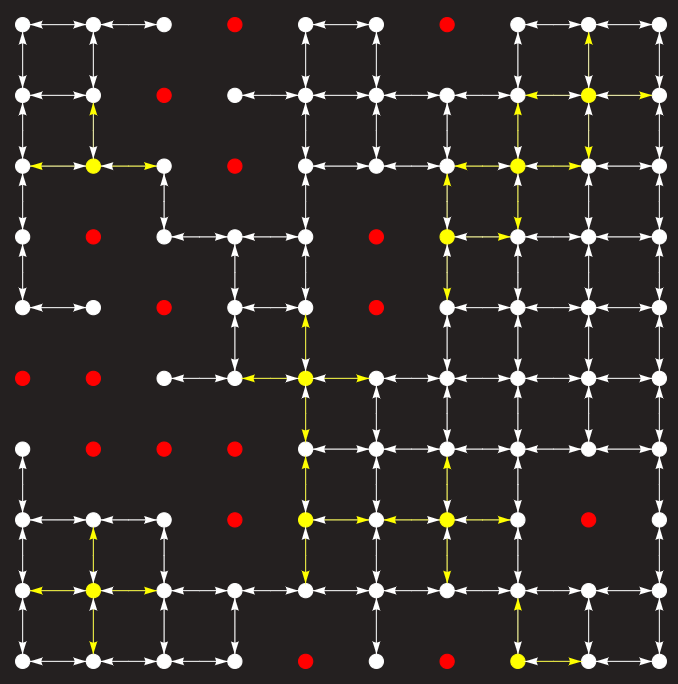

### Maze Problem formulation

Explore the derived *class MazeProblem(Problem)* for our Maze World example

In [49]:
from src.mazeProblemClass import MazeProblem

In [61]:
initState, goalState=(4,0),(2,1)

In [62]:
mp1=MazeProblem(initState,goalState,mazeWorldGraph2)

In [63]:
testState=(1,0)

In [64]:
mp1.actions(testState)

['up', 'right', 'down']

Let's check that the Euclidean distance between one and two dimensional points (a start & a goal) calculated correctly

In [65]:
from src.nodeClass import Node

In [66]:
import math

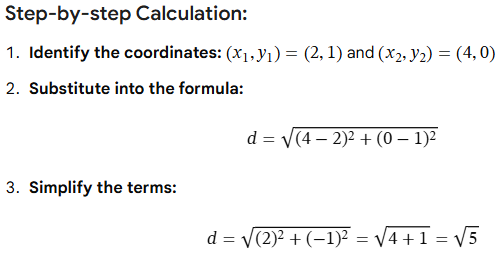

In [67]:
node = Node(mp1.initial)
print(node.path_cost+round(math.dist(node.state, mp1.goal),2)) 

2.24


## Problem Solving Agent in PacMan World

We also need to develop  the `A_StarSearchAgentProgram` to process Pacman World with A* algorithm.

In [70]:
from src.PS_agentPrograms import A_StarSearchAgentProgram

Now we need to create the instance of the A* based on Euclidean distance used for h(n)

In [75]:
f1=A_StarSearchAgentProgram(math.dist)

Check how it works with our instance of the Pacman world

In [72]:
f1(mp1)

Hi
[(2.236, <Node (4, 0)>)]
The node (4, 0) is extracted from frontier:
The child node <Node (3, 0)>.
The child node <Node (4, 1)>.
[(2.0, <Node (4, 1)>), (3.4139999999999997, <Node (3, 0)>)]
The node (4, 1) is extracted from frontier:
[(3.4139999999999997, <Node (3, 0)>)]
The node (3, 0) is extracted from frontier:
The child node <Node (2, 0)>.
[(5.0, <Node (2, 0)>)]
The node (2, 0) is extracted from frontier:
The child node <Node (1, 0)>.
The child node <Node (2, 1)>.
[(4.0, <Node (2, 1)>), (7.414, <Node (1, 0)>)]
The node (2, 1) is extracted from frontier:
We have found our goal: (2, 1)


<Node (2, 1)>

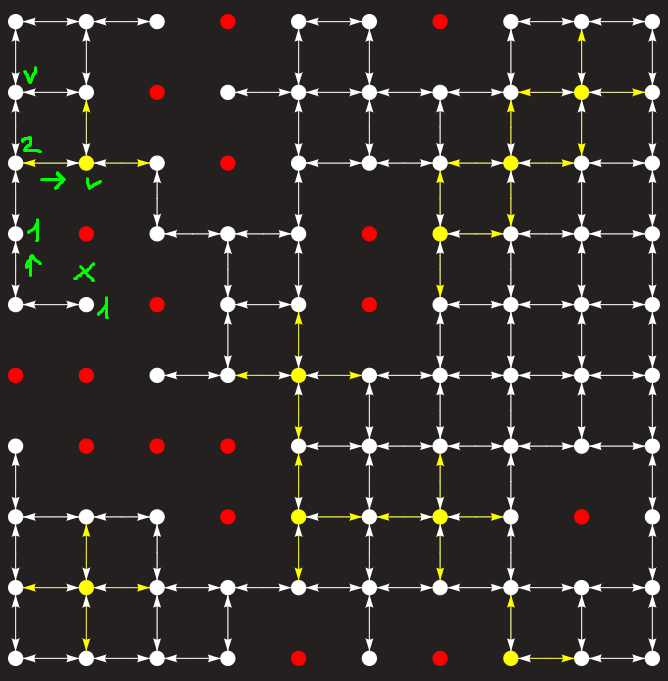

Perfect! We are ready to create the PS PacMan Agent based on this AP.

In [73]:
from src.agents import ProblemSolvingMazeAgentAstar

In [76]:
initState, goalState=(4,0),(2,1)

In [78]:
Astar_PacManAgent1=ProblemSolvingMazeAgentAstar(initState,mazeWorldGraph2,goalState)

In [79]:
Astar_PacManAgent1.goal

(2, 1)

In [80]:
testNode=(0,0)

In [81]:
Astar_PacManAgent1.program(mp1)

Hi
[(2.236, <Node (4, 0)>)]
The node (4, 0) is extracted from frontier:
The child node <Node (3, 0)>.
The child node <Node (4, 1)>.
[(2.0, <Node (4, 1)>), (3.4139999999999997, <Node (3, 0)>)]
The node (4, 1) is extracted from frontier:
[(3.4139999999999997, <Node (3, 0)>)]
The node (3, 0) is extracted from frontier:
The child node <Node (2, 0)>.
[(5.0, <Node (2, 0)>)]
The node (2, 0) is extracted from frontier:
The child node <Node (1, 0)>.
The child node <Node (2, 1)>.
[(4.0, <Node (2, 1)>), (7.414, <Node (1, 0)>)]
The node (2, 1) is extracted from frontier:
We have found our goal: (2, 1)


<Node (2, 1)>

In [82]:
Astar_PacManAgent1(testNode)

Hi, I have the only goal: (2, 1)
Hi
[(2.236, <Node (0, 0)>)]
The node (0, 0) is extracted from frontier:
The child node <Node (0, 1)>.
The child node <Node (1, 0)>.
[(2.0, <Node (0, 1)>), (2.4139999999999997, <Node (1, 0)>)]
The node (0, 1) is extracted from frontier:
The child node <Node (0, 2)>.
The child node <Node (1, 1)>.
[(2.0, <Node (1, 1)>), (2.4139999999999997, <Node (1, 0)>), (2.236, <Node (0, 2)>)]
The node (1, 1) is extracted from frontier:
The child node <Node (2, 1)>.
[(2.0, <Node (2, 1)>), (2.4139999999999997, <Node (1, 0)>), (2.236, <Node (0, 2)>)]
The node (2, 1) is extracted from frontier:
We have found our goal: (2, 1)
Solution (a sequence of actions) from the initial state to a goal: ['right', 'down', 'down']


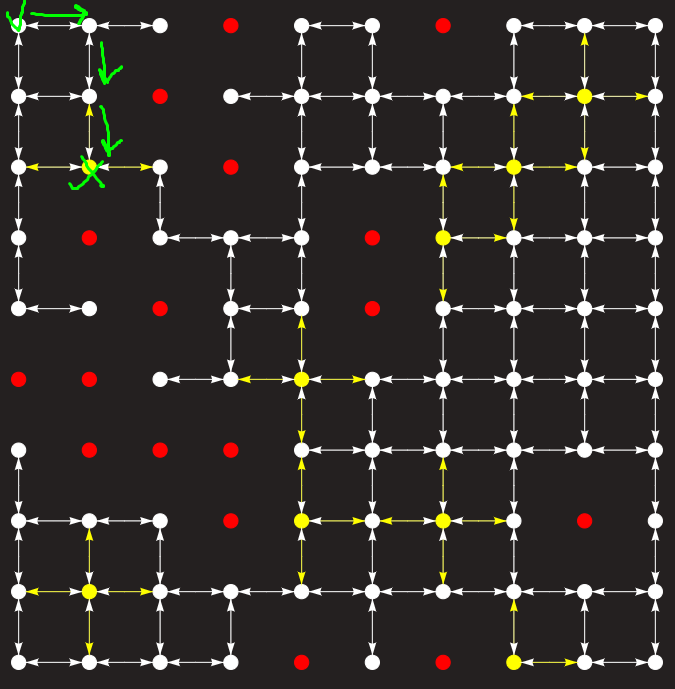

In [83]:
Astar_PacManAgent1(testNode)

I have already don my work. Find someone else


Let's create the **environment for our PacMan World**

In [84]:
from src.naigationEnvironmentClass import MazeNavigationEnvironment

In [85]:
PacmanWorld1=MazeNavigationEnvironment(mazeWorldGraph2)

In [86]:
PacmanWorld1.status.graph_dict

{(0, 0): {(0, 1): 0, (1, 0): 1},
 (0, 1): {(0, 0): 0, (0, 2): 0, (1, 1): 1},
 (0, 2): {(0, 1): 0},
 (0, 4): {(0, 5): 0, (1, 4): 1},
 (0, 5): {(0, 4): 0, (1, 5): 1},
 (0, 7): {(0, 8): 0, (1, 7): 1},
 (0, 8): {(0, 7): 0, (0, 9): 0, (1, 8): 1},
 (0, 9): {(0, 8): 0, (1, 9): 1},
 (1, 0): {(0, 0): 2, (1, 1): 0, (2, 0): 1},
 (1, 1): {(1, 0): 0, (0, 1): 2, (2, 1): 1},
 (1, 3): {(1, 4): 0},
 (1, 4): {(1, 3): 0, (0, 4): 2, (1, 5): 0, (2, 4): 1},
 (1, 5): {(1, 4): 0, (0, 5): 2, (1, 6): 0, (2, 5): 1},
 (1, 6): {(1, 5): 0, (1, 7): 0, (2, 6): 1},
 (1, 7): {(1, 6): 0, (0, 7): 2, (1, 8): 0, (2, 7): 1},
 (1, 8): {(1, 7): 0, (0, 8): 2, (1, 9): 0, (2, 8): 1},
 (1, 9): {(1, 8): 0, (0, 9): 2, (2, 9): 1},
 (2, 0): {(1, 0): 2, (2, 1): 0, (3, 0): 1},
 (2, 1): {(2, 0): 0, (1, 1): 2, (2, 2): 0},
 (2, 2): {(2, 1): 0, (3, 2): 1},
 (2, 4): {(1, 4): 2, (2, 5): 0, (3, 4): 1},
 (2, 5): {(2, 4): 0, (1, 5): 2, (2, 6): 0},
 (2, 6): {(2, 5): 0, (1, 6): 2, (2, 7): 0, (3, 6): 1},
 (2, 7): {(2, 6): 0, (1, 7): 2, (2, 8): 0, 

In [87]:
goalState=(5,4)
initState,goalState

((4, 0), (5, 4))

In [88]:
Astar_PacManAgent2=ProblemSolvingMazeAgentAstar(initState,mazeWorldGraph2,goalState)

In [89]:
Astar_PacManAgent2.performance

83

In [90]:
mp2=MazeProblem(initState,goalState,mazeWorldGraph2)

In [91]:
Astar_PacManAgent2.program(mp2)

Hi
[(4.123, <Node (4, 0)>)]
The node (4, 0) is extracted from frontier:
The child node <Node (3, 0)>.
The child node <Node (4, 1)>.
[(3.162, <Node (4, 1)>), (6.472, <Node (3, 0)>)]
The node (4, 1) is extracted from frontier:
[(6.472, <Node (3, 0)>)]
The node (3, 0) is extracted from frontier:
The child node <Node (2, 0)>.
[(9.0, <Node (2, 0)>)]
The node (2, 0) is extracted from frontier:
The child node <Node (1, 0)>.
The child node <Node (2, 1)>.
[(8.243, <Node (2, 1)>), (11.657, <Node (1, 0)>)]
The node (2, 1) is extracted from frontier:
The child node <Node (1, 1)>.
The child node <Node (2, 2)>.
[(7.606, <Node (2, 2)>), (11.657, <Node (1, 0)>), (11.0, <Node (1, 1)>)]
The node (2, 2) is extracted from frontier:
The child node <Node (3, 2)>.
[(7.827999999999999, <Node (3, 2)>), (11.657, <Node (1, 0)>), (11.0, <Node (1, 1)>)]
The node (3, 2) is extracted from frontier:
The child node <Node (3, 3)>.
[(7.236000000000001, <Node (3, 3)>), (11.657, <Node (1, 0)>), (11.0, <Node (1, 1)>)]
The 

<Node (5, 4)>

In [92]:
Astar_PacManAgent2((2,2)) # place the Agent  at (2-2)

Hi, I have the only goal: (5, 4)
Hi
[(3.606, <Node (2, 2)>)]
The node (2, 2) is extracted from frontier:
The child node <Node (2, 1)>.
The child node <Node (3, 2)>.
[(3.828, <Node (3, 2)>), (4.243, <Node (2, 1)>)]
The node (3, 2) is extracted from frontier:
The child node <Node (3, 3)>.
[(3.236, <Node (3, 3)>), (4.243, <Node (2, 1)>)]
The node (3, 3) is extracted from frontier:
The child node <Node (3, 4)>.
The child node <Node (4, 3)>.
[(3.0, <Node (3, 4)>), (4.243, <Node (2, 1)>), (3.4139999999999997, <Node (4, 3)>)]
The node (3, 4) is extracted from frontier:
The child node <Node (2, 4)>.
The child node <Node (4, 4)>.
[(3.0, <Node (4, 4)>), (3.4139999999999997, <Node (4, 3)>), (6.0, <Node (2, 4)>), (4.243, <Node (2, 1)>)]
The node (4, 4) is extracted from frontier:
The child node <Node (5, 4)>.
[(3.0, <Node (5, 4)>), (3.4139999999999997, <Node (4, 3)>), (6.0, <Node (2, 4)>), (4.243, <Node (2, 1)>)]
The node (5, 4) is extracted from frontier:
We have found our goal: (5, 4)
Solution (

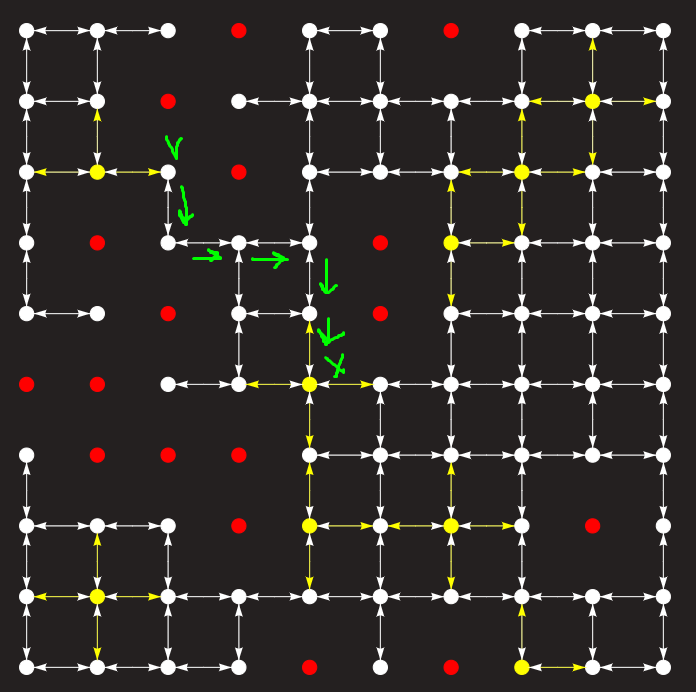

In [93]:
print(initState,goalState)

(4, 0) (5, 4)


In [94]:
intTupleTostr(goalState)

'5-4'

In [97]:
nodeColors

{'wall': 'red',
 'path': 'white',
 'food': 'yellow',
 'goal': 'green',
 'init': 'gold'}

In [98]:
nodeColors.setdefault('goal', "green")
nodeColors.setdefault('init', "gold")
nodeColors

{'wall': 'red',
 'path': 'white',
 'food': 'yellow',
 'goal': 'green',
 'init': 'gold'}

In [99]:
for node in net_maze.nodes:
    if node['id']==intTupleTostr(goalState):
        node['color']=nodeColors['goal']
    elif node['id']==intTupleTostr(initState):
        node['color']=nodeColors['init']

In [100]:
net_maze.show("PacmanWorld1.html", notebook=False)

PacmanWorld1.html


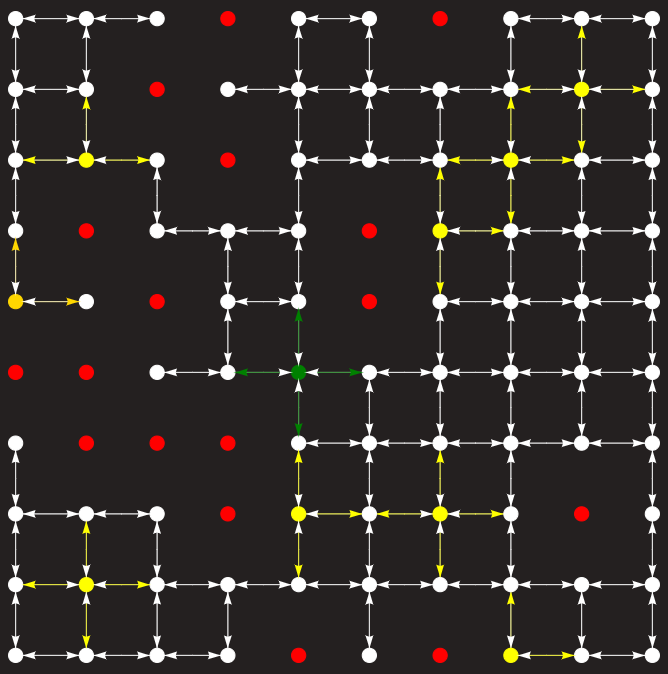

When we add the PS Agent into the Nav.Env. it should run its call() method 

In [101]:
Astar_PacManAgent3=ProblemSolvingMazeAgentAstar(initState,mazeWorldGraph2,goalState)

In [102]:
Astar_PacManAgent3.performance

83

In [103]:
PacmanWorld1.add_thing(Astar_PacManAgent3)

Hi, I have the only goal: (5, 4)
Hi
[(4.123, <Node (4, 0)>)]
The node (4, 0) is extracted from frontier:
The child node <Node (3, 0)>.
The child node <Node (4, 1)>.
[(3.162, <Node (4, 1)>), (6.472, <Node (3, 0)>)]
The node (4, 1) is extracted from frontier:
[(6.472, <Node (3, 0)>)]
The node (3, 0) is extracted from frontier:
The child node <Node (2, 0)>.
[(9.0, <Node (2, 0)>)]
The node (2, 0) is extracted from frontier:
The child node <Node (1, 0)>.
The child node <Node (2, 1)>.
[(8.243, <Node (2, 1)>), (11.657, <Node (1, 0)>)]
The node (2, 1) is extracted from frontier:
The child node <Node (1, 1)>.
The child node <Node (2, 2)>.
[(7.606, <Node (2, 2)>), (11.657, <Node (1, 0)>), (11.0, <Node (1, 1)>)]
The node (2, 2) is extracted from frontier:
The child node <Node (3, 2)>.
[(7.827999999999999, <Node (3, 2)>), (11.657, <Node (1, 0)>), (11.0, <Node (1, 1)>)]
The node (3, 2) is extracted from frontier:
The child node <Node (3, 3)>.
[(7.236000000000001, <Node (3, 3)>), (11.657, <Node (1, 

In [104]:
PacmanWorld1.run()

step 1:
Agent decided to do up.
Agent in up with performance = 82
step 2:
Agent decided to do up.
Agent in up with performance = 81
step 3:
Agent decided to do right.
Agent in right with performance = 80
step 4:
Agent decided to do right.
Agent in right with performance = 79
step 5:
Agent decided to do down.
Agent in down with performance = 78
step 6:
Agent decided to do right.
Agent in right with performance = 77
step 7:
Agent decided to do right.
Agent in right with performance = 76
step 8:
Agent decided to do down.
Agent in down with performance = 75
step 9:
Agent decided to do down.
Agent in down with performance = 74
Agent reached all goals


## Tasks

In your PacMan World the food locations (Fixed Food Dots) are 5% of the space and distributed randomly (even the start and finish points may contain food).

1. Refine the given implementaion of the A* search by outputting the number of nodes expanded on the way to the goal ('green' cell) and the total cost of the path.

2. Implement a different version of the A* search based on:
* a **Manhattan distance** as the heuristic function

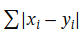

Compare the results with previous version (in the guidance above) of the algorithm. Visualize the path using differrent colors for its components (from the start to goal1, from the goal1 to.., etc.)

3. Create the refined PacMan World:
* there are 5 Ghosts (derived class from Thing class) hidden in the Maze (the PacMan Agent can't figure out the location of the ghost in advance). They are placead in the Maze randomly, but not in the start and finish points, the locations of Fixed Food Dots and Ghosts must also be different. Ghosts have a Power (random values in the range 20% -30% of space cells).

4. The Pac-man Agent must find all Fixed Food Dots and then find the finish point -> a set of goals (the results of task 2 are supposed to be used). The search of Fixed Food Dots must be rational: the 1st 'food' goal must be the most cost-optimal among other Food Dots. Try to design the appropriate heuristic for this case.

5. The inital perforamnce of Agent is 40% of space cells. After reaching a Fixed Food Dot the agent's performance doubles. 

6. If the Agent encounters Ghosts (based on its ability to regognize the types of things in the cell during perception), it fights. But only the strong Agent (with performance > Ghost's Power) can win. Otherwise the Agent will be killed by Ghost. If the Agent wins, he will lose 10% of his previous effectiveness after the battle.

7. Implemet IDA* search and apply it for tasks 4-5.

8. Implemet Recursive best-first search (RBFS)​  and apply it for tasks 4-5.

**Iterative-deepening A∗ search (IDA∗)**

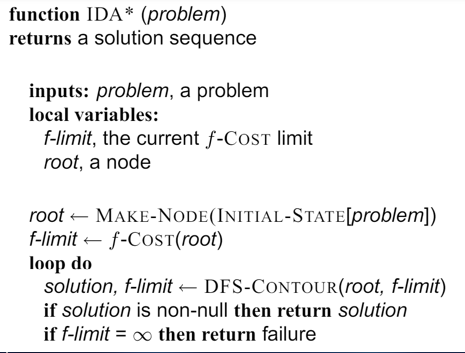

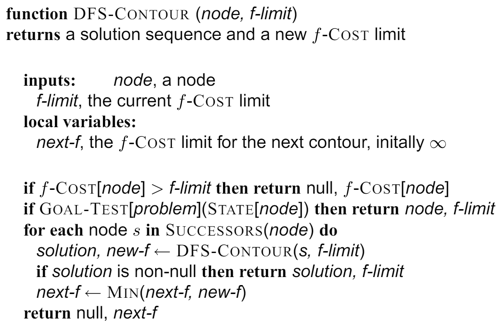

**Recursive best-first search (RBFS)​**

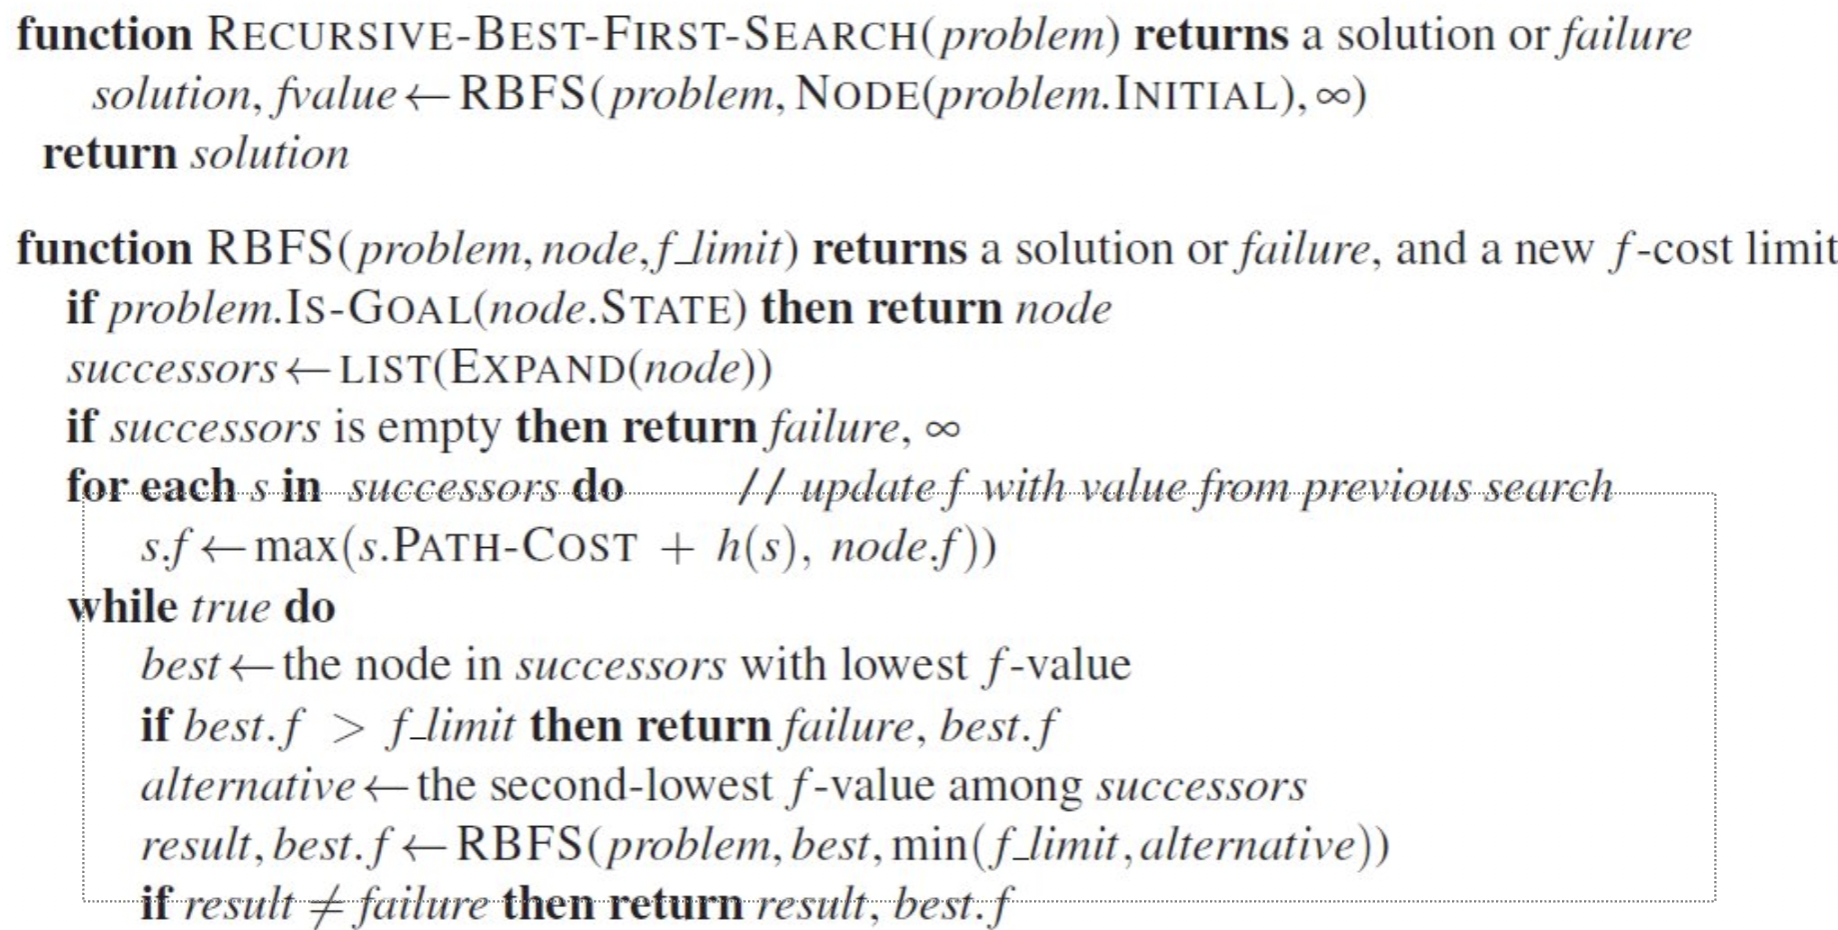

# Solutions

The code for the tasks is in `src/`, so the notebook only has to call it:

| File | What it contains | Task |
|---|---|---|
| `src/PS_agentPrograms.py` | refined **A\*** (counts expanded nodes, reports the path cost), **IDA\***, **RBFS** | 1, 7, 8 |
| `src/heuristics.py` | Euclidean, **Manhattan**, and a new **maze-cost heuristic** designed for this maze | 2, 4 |
| `src/pacmanData.py` | PacMan World generator (5 % food), graph builder, drawing helpers | 2–8 |
| `src/pacmanThings.py` | `Food` and `Ghost`, both derived from `Thing` | 3 |
| `src/pacmanAgentClass.py` | `PacmanAgent`, which plans one route through a *set* of goals | 2, 4, 5, 6 |
| `src/pacmanEnvironmentClass.py` | `PacmanWorldEnvironment`: food, hidden ghosts, performance, fights | 3, 5, 6 |
| `src/agents.py` | `PacmanAgentAstar`, `PacmanAgentIDAstar`, `PacmanAgentRBFS` | 4, 7, 8 |
| `src/thingClass.py` | the `Thing` base class (it was missing from the repository) | 3 |

**Bugs fixed in the given code**
* `defineMazeAvailableActions`, bottom-right corner: the `left` / `up` checks were swapped, so from cell (n-1, n-1) Pac-Man could walk into a wall.
* `A_StarSearchAgentProgram`: `while frontier:` is always true for a `PriorityQueue`, so the search waited forever when the goal could not be reached.

**Keep the step costs in mind for every task.** `mazeGraph` gives each move a cost: **up = 2, down = 1, left = right = 0**. Moving sideways is free, so a straight-line distance is *not* a lower bound on the real cost.
(The agent's *performance* is a different thing: every move, of any kind, costs Pac-Man 1 performance point.)

In [1]:
import math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.mazeProblemClass import MazeProblem
from src.PS_agentPrograms import A_StarSearchAgentProgram, IDA_StarSearchAgentProgram, RBFSAgentProgram
from src.heuristics import euclideanDistance, manhattanDistance, mazeCostHeuristic, zeroHeuristic
from src.pacmanData import (makePacmanMaze, buildPacmanGraph, drawPacmanWorld, pacmanPyvis,
                            plotPerformance, exactCostsFrom, bestFoodOrder, reachableCells)
from src.agents import PacmanAgentAstar, PacmanAgentIDAstar, PacmanAgentRBFS
from src.pacmanEnvironmentClass import PacmanWorldEnvironment

## The PacMan World used for the tasks

`makePacmanMaze` builds an n × n maze with 20 % walls and exactly **5 % food dots** (5 dots when n = 10), placed at random. The start and the exit may also get food.
A world is only accepted if the exit and every food dot can be reached from the start; otherwise the task would be impossible.
The fixed `SEED` makes every result below repeatable. Change it to get a new world.

In [2]:
n = 10
SEED = 67
SPACE = n * n        # "space cells" = all cells of the maze -> 100

maze, start, exit_, foods = makePacmanMaze(n, seed=SEED)
graph = buildPacmanGraph(maze)
print("start:", start, "| exit:", exit_)
print("food dots (in the order they were placed):", foods)
maze

start: (7, 1) | exit: (3, 0)
food dots (in the order they were placed): [(1, 9), (1, 6), (7, 8), (4, 9), (4, 1)]


array([[1, 1, 1, 1, 0, 0, 1, 1, 1, 0],
       [1, 1, 1, 1, 0, 1, 2, 1, 1, 2],
       [0, 1, 0, 1, 1, 1, 0, 1, 1, 1],
       [1, 1, 1, 1, 0, 0, 0, 1, 1, 1],
       [1, 2, 1, 1, 1, 1, 1, 1, 1, 2],
       [1, 1, 0, 0, 0, 1, 1, 1, 1, 0],
       [1, 1, 0, 1, 1, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 1, 0, 1, 2, 0],
       [1, 1, 0, 1, 1, 0, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 1, 1, 1, 0, 1]])

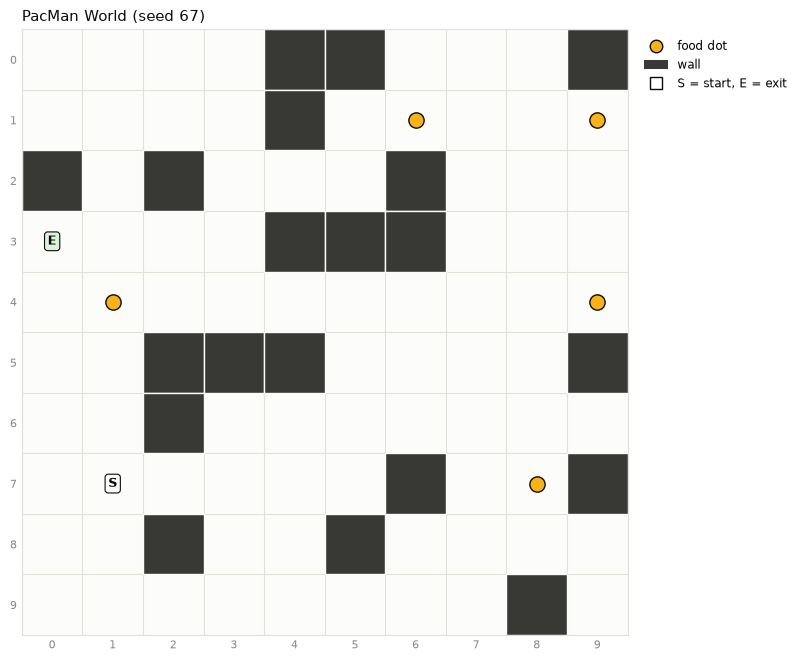

<Axes: title={'left': 'PacMan World (seed 67)'}>

In [3]:
drawPacmanWorld(maze, start, exit_, foods, title=f"PacMan World (seed {SEED})")

## Task 1 — A* that reports the nodes expanded and the path cost

Changes to `A_StarSearchAgentProgram` in `src/PS_agentPrograms.py`:
* It **counts every node it expands**, meaning each node it takes out of the frontier and generates children for. When it reaches the goal it prints the **number of expanded nodes**, the **total path cost** g(goal) and the number of moves. The same numbers are kept in `program.stats`.
* It uses the heuristic you pass in for the start node as well (that line was hard-coded to `math.dist`).
* `while not frontier.empty()`: if no path exists it returns `None` instead of hanging.
* It skips old frontier entries for a state that was later reached by a cheaper path.
* **Tie-break:** when two nodes have the same f, the one with fewer moves goes first. The path cost stays the same; Pac-Man just avoids pointless free sideways steps, which matters because every step costs it 1 performance point.

The old call `A_StarSearchAgentProgram(math.dist)` still works and prints the same trace as in the tutorial.
First a short search with the full trace, then start → exit with only the summary line:

In [4]:
astar_trace = A_StarSearchAgentProgram(euclideanDistance)        # verbose, like the tutorial
node = astar_trace(MazeProblem(start, (4, 1), graph))             # start -> the nearest food dot

Hi
[(3.0, <Node (7, 1)>)]
The node (7, 1) is extracted from frontier:
The child node <Node (7, 0)>.
The child node <Node (6, 1)>.
The child node <Node (7, 2)>.
The child node <Node (8, 1)>.
[(3.162, <Node (7, 0)>), (4.0, <Node (6, 1)>), (3.162, <Node (7, 2)>), (5.0, <Node (8, 1)>)]
The node (7, 0) is extracted from frontier:
The child node <Node (6, 0)>.
The child node <Node (8, 0)>.
[(3.162, <Node (7, 2)>), (4.0, <Node (6, 1)>), (5.0, <Node (8, 1)>), (4.236000000000001, <Node (6, 0)>), (5.123, <Node (8, 0)>)]
The node (7, 2) is extracted from frontier:
The child node <Node (7, 3)>.
[(3.606, <Node (7, 3)>), (4.0, <Node (6, 1)>), (5.0, <Node (8, 1)>), (5.123, <Node (8, 0)>), (4.236000000000001, <Node (6, 0)>)]
The node (7, 3) is extracted from frontier:
The child node <Node (6, 3)>.
The child node <Node (7, 4)>.
The child node <Node (8, 3)>.
[(4.0, <Node (6, 1)>), (4.236000000000001, <Node (6, 0)>), (4.243, <Node (7, 4)>), (5.123, <Node (8, 0)>), (4.827999999999999, <Node (6, 3)>), (5.0

In [5]:
astar_euclid = A_StarSearchAgentProgram(euclideanDistance, verbose=False)
goal_node = astar_euclid(MazeProblem(start, exit_, graph))

print("path   :", [nd.state for nd in goal_node.path()])
print("actions:", goal_node.solution())
print("stats  :", astar_euclid.stats)

[A* | h=euclideanDistance] goal (3, 0) reached | nodes expanded: 19 | path cost: 8 | steps: 5
path   : [(7, 1), (7, 0), (6, 0), (5, 0), (4, 0), (3, 0)]
actions: ['left', 'up', 'up', 'up', 'up']
stats  : {'algorithm': 'A*', 'heuristic': 'euclideanDistance', 'nodes_expanded': 19, 'nodes_generated': 60, 'max_frontier': 9, 'peak_memory': 28, 'path_cost': 8, 'steps': 5, 'goal': (3, 0)}


## Task 2 — A* with the Manhattan distance

$$h_{Manhattan}(n) = \sum_i |x_i - y_i| = |row_n - row_{goal}| + |col_n - col_{goal}|$$

This is the number of grid moves needed if there were no walls. It is `manhattanDistance` in `src/heuristics.py`.
The A* code stays the same; only the heuristic changes: `A_StarSearchAgentProgram(manhattanDistance)`.

### 2a. The same problems with both heuristics
Start → each food dot, and start → exit. The column *optimal cost* is the true cheapest cost, computed with uniform-cost search (Dijkstra, which is A* with h = 0).

In [6]:
def astarStats(h, s, g, world_graph=graph):
    prog = A_StarSearchAgentProgram(h, verbose=False, report=False)
    prog(MazeProblem(s, g, world_graph))
    return prog.stats

exact = exactCostsFrom(graph, start)       # true cheapest cost from the start to every cell
rows = []
for target in foods + [exit_]:
    e = astarStats(euclideanDistance, start, target)
    m = astarStats(manhattanDistance, start, target)
    rows.append({'goal': str(target), 'optimal cost': exact[target],
                 'Euclidean: expanded': e['nodes_expanded'], 'Euclidean: cost': e['path_cost'],
                 'Manhattan: expanded': m['nodes_expanded'], 'Manhattan: cost': m['path_cost']})
table = pd.DataFrame(rows).set_index('goal')
table.loc['TOTAL'] = table.sum()
table

,optimal cost,Euclidean: expanded,Euclidean: cost,Manhattan: expanded,Manhattan: cost
goal,,,,,
"(1, 9)",12,42,12,26,12
"(1, 6)",12,62,12,42,12
"(7, 8)",3,10,3,10,3
"(4, 9)",6,15,6,13,6
"(4, 1)",6,15,6,8,6
"(3, 0)",8,19,8,12,8
TOTAL,47,163,47,111,47


### 2b. A bigger test: 100 random worlds × 10 random start/goal pairs
One world is not enough to compare heuristics, so the same A* runs with each heuristic on 1000 problems.
Two more rows are included for reference: the heuristic designed in Task 4 and h = 0 (uniform-cost search, which is always optimal).

In [7]:
H = {'Euclidean': euclideanDistance, 'Manhattan': manhattanDistance,
     'maze-cost (Task 4)': mazeCostHeuristic, 'h = 0 (uniform cost)': zeroHeuristic}
res = {k: {'avg nodes expanded': 0, 'avg path cost': 0, 'optimal paths %': 0} for k in H}
N = 0
for k in range(100):
    m_, s_, e_, f_ = makePacmanMaze(10, seed=1000 + k)
    g_ = buildPacmanGraph(m_)
    cells_ = sorted(reachableCells(m_, s_))
    rng = np.random.default_rng(k)
    for _ in range(10):
        a, b = [cells_[i] for i in rng.choice(len(cells_), 2, replace=False)]
        best = exactCostsFrom(g_, a)[b]
        N += 1
        for name, h in H.items():
            st = astarStats(h, a, b, g_)
            res[name]['avg nodes expanded'] += st['nodes_expanded']
            res[name]['avg path cost'] += st['path_cost']
            res[name]['optimal paths %'] += (st['path_cost'] == best)
summary = pd.DataFrame(res).T / N
summary['optimal paths %'] *= 100
print("problems:", N)
summary.round(2)

problems: 1000


,avg nodes expanded,avg path cost,optimal paths %
Euclidean,16.28,5.56,99.5
Manhattan,12.72,5.55,99.8
maze-cost (Task 4),15.32,5.55,100.0
h = 0 (uniform cost),36.51,5.55,100.0


**What the comparison shows**
* **Manhattan expands fewer nodes than Euclidean** (about 20 % fewer). Manhattan is never smaller than Euclidean, so f grows faster on paths that lead away from the goal and A\* wastes less time on them.
* **Neither heuristic guarantees the cheapest path here.** A\* is only guaranteed to be optimal when h never *overestimates* the true cost (an *admissible* heuristic). Because left/right moves are free, both distances can overestimate: a goal 5 cells to the right costs 0, but h = 5. In this test 5 of 1000 Euclidean paths and 2 of 1000 Manhattan paths cost more than the optimum (in 20 × 20 mazes it was about 5 % and 4 %).
* Uniform-cost search (h = 0) is always optimal but expands the most nodes. The Task 4 heuristic is also always optimal and needs less than half of uniform-cost search's expansions.

### 2c. Visiting a set of goals, with each leg in its own colour
`PacmanAgent` receives a **list of goals**: every food dot, then the exit. Here (`rational=False`) it visits the food in the order the dots were listed, which is not a smart order yet; that comes in Task 4.
Each leg is a separate A* search: leg 1 = start → goal 1, leg 2 = goal 1 → goal 2, and so on. A food dot passed on the way is eaten and dropped from the list.
In the picture each leg has its own colour, and the small number next to a food dot is the order in which it is eaten.

In [8]:
listed_e = PacmanAgentAstar(start, graph, foods, exit_, SPACE, h=euclideanDistance,
                            rational=False, name='A* Euclidean, listed order')
listed_e(start)
listed_m = PacmanAgentAstar(start, graph, foods, exit_, SPACE, h=manhattanDistance,
                            rational=False, name='A* Manhattan, listed order')
listed_m(start)

A* Euclidean, listed order route plan (given order):
  leg 1: (7, 1) -> (1, 9) (food) | cost 12 | steps 14 | nodes expanded 42
  leg 2: (1, 9) -> (1, 6) (food) | cost 0 | steps 3 | nodes expanded 3
  leg 3: (1, 6) -> (7, 8) (food) | cost 6 | steps 8 | nodes expanded 8
  leg 4: (7, 8) -> (4, 1) (food) | cost 9 | steps 12 | nodes expanded 23
  leg 5: (4, 1) -> (3, 0) (exit) | cost 2 | steps 2 | nodes expanded 2
  TOTAL: cost 29 | steps 39 | nodes expanded 78
A* Manhattan, listed order route plan (given order):
  leg 1: (7, 1) -> (1, 9) (food) | cost 12 | steps 14 | nodes expanded 26
  leg 2: (1, 9) -> (1, 6) (food) | cost 0 | steps 3 | nodes expanded 3
  leg 3: (1, 6) -> (7, 8) (food) | cost 6 | steps 8 | nodes expanded 8
  leg 4: (7, 8) -> (4, 1) (food) | cost 9 | steps 12 | nodes expanded 17
  leg 5: (4, 1) -> (3, 0) (exit) | cost 2 | steps 2 | nodes expanded 2
  TOTAL: cost 29 | steps 39 | nodes expanded 56


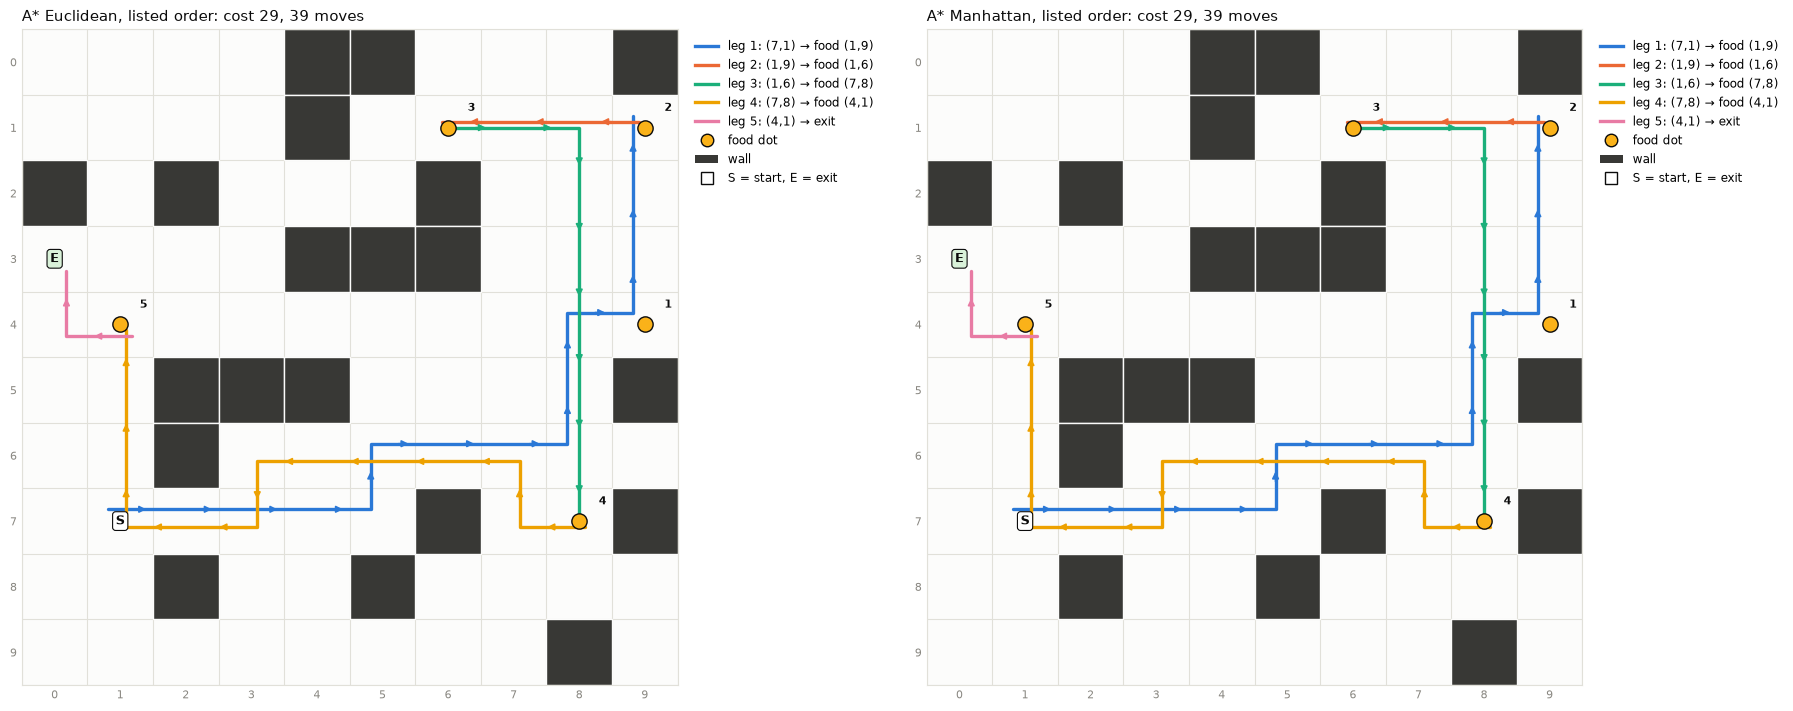

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(18, 7), layout='constrained')
for ax, ag in zip(axs, [listed_e, listed_m]):
    drawPacmanWorld(maze, start, exit_, foods, segments=ag.segments, ax=ax, food_order=ag.food_order,
                    title=f"{ag.name}: cost {ag.total_cost}, {ag.total_steps} moves")
plt.show()

In [10]:
# the same route as an interactive PyVis graph (open the HTML file in a browser)
pacmanPyvis(graph, maze, start, exit_, listed_m.segments, filename='PacmanWorld_Task2_route.html',
            heading='Task 2 - route in listed order (A* Manhattan)')

'PacmanWorld_Task2_route.html'

In this world both heuristics give the same route cost (29), but Manhattan needs fewer node expansions to find it (56 vs 78).
Look at the route itself: the listed order first sends Pac-Man to the far top-right corner (cost 12, mostly expensive up-moves) and then back down. Task 4 fixes this.

## Task 3 — Refined PacMan World with 5 hidden Ghosts

* `Ghost(Thing)` and `Food(Thing)` are defined in `src/pacmanThings.py`. A ghost has a `power`.
* `PacmanWorldEnvironment` places **5 ghosts at random open cells**, never on the start, the exit, a food dot or another ghost.
* Power = a random integer between **20 % and 30 % of the space cells** (20–30 for a 10 × 10 maze).
* The ghosts are **hidden**: the agent is only told where the food dots and the exit are. Ghost positions exist only inside the environment, and the agent's percept contains only the things in its *own* cell.

ghosts (location, power): [((1, 2), 24), ((2, 1), 29), ((7, 3), 26), ((8, 4), 27), ((7, 4), 29)]
all placement rules hold


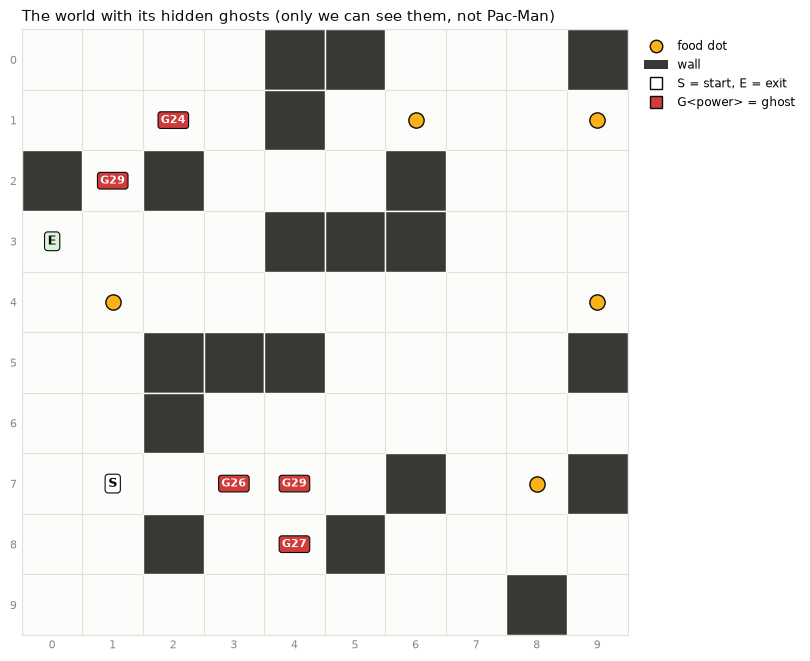

<Axes: title={'left': 'The world with its hidden ghosts (only we can see them, not Pac-Man)'}>

In [11]:
world = PacmanWorldEnvironment(maze, start, exit_, n_ghosts=5, seed=SEED, verbose=False)
print("ghosts (location, power):", world.ghosts)

ghost_cells = [cell for cell, power in world.ghosts]
assert len(set(ghost_cells)) == 5                                  # 5 different cells
assert not set(ghost_cells) & ({start, exit_} | set(foods))         # not on start, exit or food
assert all(maze[c] != 0 for c in ghost_cells)                       # not inside a wall
assert all(0.2 * SPACE <= p <= 0.3 * SPACE for c, p in world.ghosts)
print("all placement rules hold")

drawPacmanWorld(maze, start, exit_, foods, ghosts=world.ghosts,
                title="The world with its hidden ghosts (only we can see them, not Pac-Man)")

## Task 4 — All food dots, then the exit, in a rational order

### How the order is chosen
From where it is now, Pac-Man goes to the food dot that is **cheapest to reach**, then repeats from there. When no food is left, it goes to the exit.

This needs only one search per leg, not one search per food dot: A\* gets **the whole list of remaining food dots as its goal** (`Problem.goal_test` already accepts a list). A\* stops at the first goal it takes out of the frontier. With an admissible heuristic, that goal is the cheapest food dot to reach (see `PacmanAgent.plan_route` with `rational=True`).

### The heuristic for this case
With several goals the estimate is the distance to the **nearest** one:
$$h(n) = \min_{food \in remaining} h(n, food)$$

h(n, food) must never overestimate. Otherwise A\* could stop at a food dot that only *looks* cheapest, and Task 2 showed that Euclidean and Manhattan do overestimate here. So the heuristic is built from the step costs:
* left/right moves are free, so the horizontal distance has no guaranteed cost;
* if the food is k rows **above**, Pac-Man needs at least k up-moves, which cost at least **2k**;
* if the food is k rows **below**, Pac-Man needs at least k down-moves, which cost at least **k**.

$$h_{maze}(n, g) = \begin{cases} 2\,(row_n - row_g) & \text{goal above} \\ row_g - row_n & \text{goal below} \\ 0 & \text{same row} \end{cases}$$

It never exceeds the real cost (*admissible*), and one move changes it by at most that move's cost (*consistent*). So A\* with `mazeCostHeuristic` always returns a cheapest path, and with a list of food dots the first one it reaches is the cheapest one.

The check below compares each heuristic with the true cost for every pair of cells in this world:

In [12]:
cells = sorted(reachableCells(maze, start))
heuristics = [('Euclidean', euclideanDistance), ('Manhattan', manhattanDistance), ('maze-cost', mazeCostHeuristic)]
over = {name: 0 for name, h in heuristics}
pairs = 0
for a in cells:
    true_cost = exactCostsFrom(graph, a)
    for b in cells:
        pairs += 1
        for name, h in heuristics:
            over[name] += h(a, b) > true_cost[b]
print(f"pairs of cells checked: {pairs}")
for name, k in over.items():
    print(f"  {name:10s} overestimates the true cost for {k:5d} pairs ({100 * k / pairs:.1f} %)")

pairs of cells checked: 6400
  Euclidean  overestimates the true cost for  3781 pairs (59.1 %)
  Manhattan  overestimates the true cost for  4159 pairs (65.0 %)
  maze-cost  overestimates the true cost for     0 pairs (0.0 %)


In [13]:
rational = PacmanAgentAstar(start, graph, foods, exit_, SPACE, h=mazeCostHeuristic,
                            rational=True, name='A* maze-cost, rational order')
rational(start)

A* maze-cost, rational order route plan (rational):
  leg 1: (7, 1) -> (7, 8) (food) | cost 3 | steps 9 | nodes expanded 19
  leg 2: (7, 8) -> (4, 9) (food) | cost 6 | steps 4 | nodes expanded 5
  leg 3: (4, 9) -> (4, 1) (food) | cost 0 | steps 8 | nodes expanded 8
  leg 4: (4, 1) -> (1, 6) (food) | cost 6 | steps 8 | nodes expanded 17
  leg 5: (1, 6) -> (1, 9) (food) | cost 0 | steps 3 | nodes expanded 3
  leg 6: (1, 9) -> (3, 0) (exit) | cost 2 | steps 11 | nodes expanded 17
  TOTAL: cost 17 | steps 43 | nodes expanded 69


In [14]:
# is the 1st food goal really the cheapest one to reach from the start?
first = rational.segments[0]['goal']
print("true cost from the start to each food dot:", {f: exact[f] for f in foods})
print(f"first food chosen: {first}, cost {exact[first]} | cheapest possible: {min(exact[f] for f in foods)}")

true cost from the start to each food dot: {(1, 9): 12, (1, 6): 12, (7, 8): 3, (4, 9): 6, (4, 1): 6}
first food chosen: (7, 8), cost 3 | cheapest possible: 3


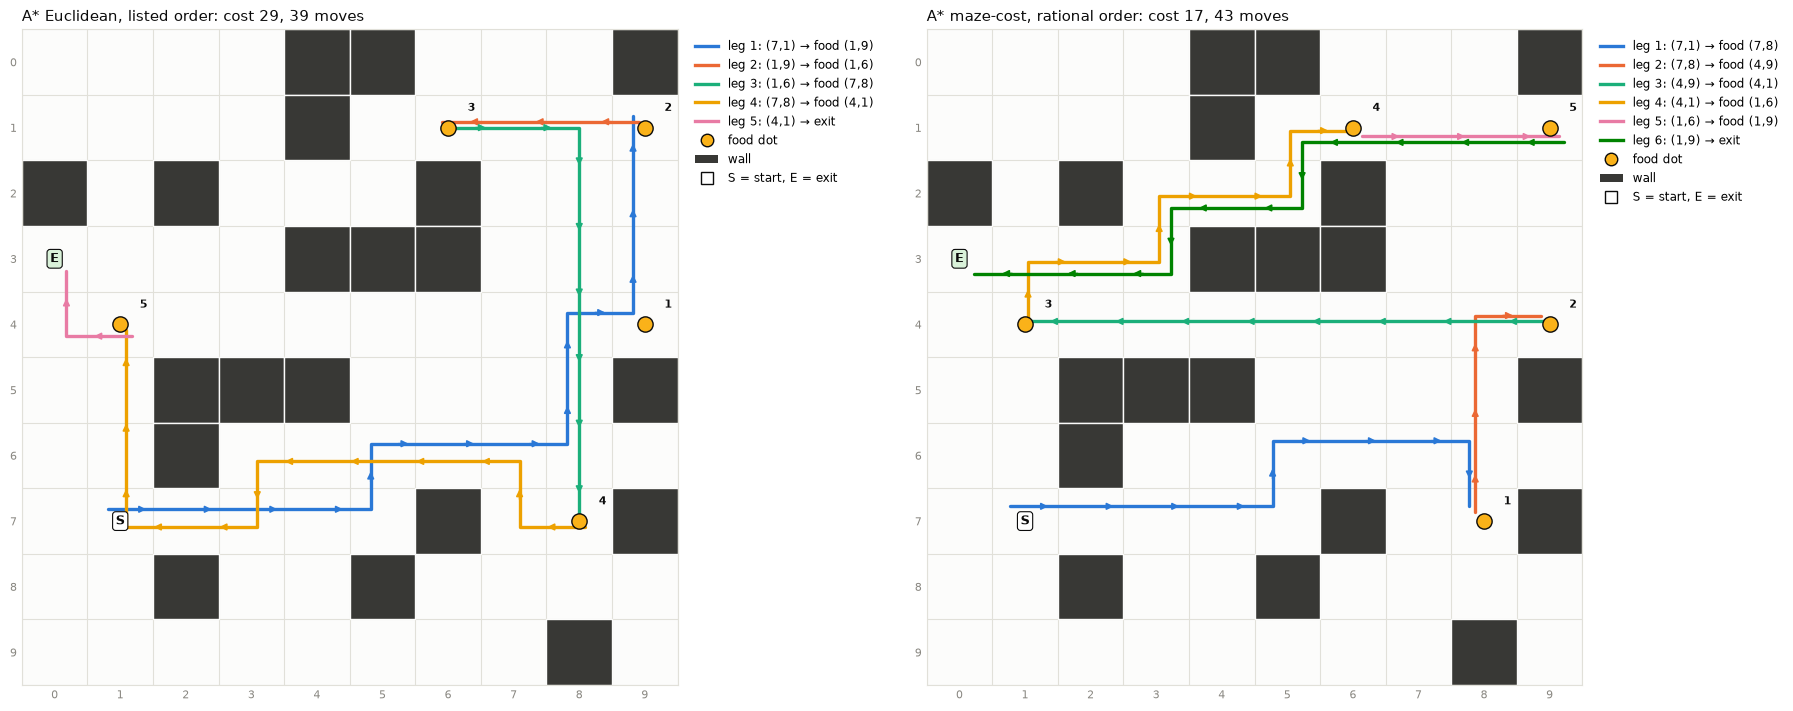

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(18, 7), layout='constrained')
for ax, ag in zip(axs, [listed_e, rational]):
    drawPacmanWorld(maze, start, exit_, foods, segments=ag.segments, ax=ax, food_order=ag.food_order,
                    title=f"{ag.name}: cost {ag.total_cost}, {ag.total_steps} moves")
plt.show()

### How good is "cheapest food first"?
Below, the greedy order is compared with the best possible order, found by brute force over all 5! = 120 orders using exact costs. First for this world, then averaged over 300 random worlds.

In [16]:
best_cost, best_order = bestFoodOrder(graph, start, exit_, [f for f in foods if f not in (start, exit_)])
pd.DataFrame({'route cost': [listed_e.total_cost, rational.total_cost, best_cost]},
             index=['listed order (Task 2)', 'rational: cheapest food first (Task 4)', 'best of all 120 orders'])

,route cost
listed order (Task 2),29
rational: cheapest food first (Task 4),17
best of all 120 orders,17


In [17]:
totals = {'listed order': 0, 'cheapest food first': 0, 'best order': 0}
greedy_is_best = 0
W = 300
for k in range(W):
    m_, s_, e_, f_ = makePacmanMaze(10, seed=k)
    g_ = buildPacmanGraph(m_)
    a1 = PacmanAgentAstar(s_, g_, f_, e_, SPACE, rational=False, verbose=False); a1(s_)  # same h, only the order differs
    a2 = PacmanAgentAstar(s_, g_, f_, e_, SPACE, rational=True, verbose=False); a2(s_)
    b, _ = bestFoodOrder(g_, s_, e_, [f for f in f_ if f not in (s_, e_)])
    totals['listed order'] += a1.total_cost
    totals['cheapest food first'] += a2.total_cost
    totals['best order'] += b
    greedy_is_best += (a2.total_cost == b)
print({k: round(v / W, 2) for k, v in totals.items()})
print(f"cheapest-food-first found the best order in {100 * greedy_is_best / W:.0f} % of the worlds")

{'listed order': 29.81, 'cheapest food first': 22.47, 'best order': 20.11}
cheapest-food-first found the best order in 60 % of the worlds


**Takeaways**
* Choosing the cheapest food first is much better than an arbitrary order: on average the route is about 25 % cheaper.
* It is not always the best order, because greedy does not look ahead. It can leave a food dot that is cheap now but expensive to come back to later, for example one *above* Pac-Man, since up-moves cost 2.
* Finding the truly best order is a travelling-salesman-type problem: n! orders. That is fine for 5 dots (120 orders) and hopeless for many dots, which is why a greedy rule with a good heuristic is the practical choice.

## Tasks 5 & 6 — Performance, food and ghost fights

Rules implemented in `PacmanWorldEnvironment`:

| Event | Effect on performance |
|---|---|
| start | **40 % of the space cells** = 40 |
| every move | −1 |
| reaching a Fixed Food Dot | **× 2** (the food is eaten and disappears) |
| meeting a ghost with performance **>** ghost power | Pac-Man **wins**, the ghost is removed, performance **× 0.9** (it loses 10 %) |
| meeting a ghost with performance **≤** ghost power | Pac-Man is **killed** and the run ends |
| performance drops to 0 | Pac-Man dies |

**Perception.** After every move the environment gives the agent a percept: *(its cell, the things in that cell)*. In `interpret_percept` the agent recognises each thing by its type: `isinstance(thing, Ghost)` means *fight* and `isinstance(thing, Food)` means *eat*. The environment then applies the result.
The route was planned before Pac-Man started moving, so it goes straight through ghosts it cannot see.

In [18]:
world_astar = PacmanWorldEnvironment(maze, start, exit_, seed=SEED, verbose='steps')
pac_astar = PacmanAgentAstar(start, graph, foods, exit_, SPACE)      # performance starts at 40
world_astar.add_thing(pac_astar)
world_astar.run()

Pac-Man (A*) route plan (rational):
  leg 1: (7, 1) -> (7, 8) (food) | cost 3 | steps 9 | nodes expanded 19
  leg 2: (7, 8) -> (4, 9) (food) | cost 6 | steps 4 | nodes expanded 5
  leg 3: (4, 9) -> (4, 1) (food) | cost 0 | steps 8 | nodes expanded 8
  leg 4: (4, 1) -> (1, 6) (food) | cost 6 | steps 8 | nodes expanded 17
  leg 5: (1, 6) -> (1, 9) (food) | cost 0 | steps 3 | nodes expanded 3
  leg 6: (1, 9) -> (3, 0) (exit) | cost 2 | steps 11 | nodes expanded 17
  TOTAL: cost 17 | steps 43 | nodes expanded 69
t=  0 | Pac-Man (A*) starts at (7, 1) with performance 40
step 1: right -> (7, 2) | performance 39
step 2: right -> (7, 3) | performance 38
t=  2 | met a ghost (power 26) at (7, 3) and WON: performance 38 -> 34.2
step 3: right -> (7, 4) | performance 33.2
t=  3 | met a ghost (power 29) at (7, 4) and WON: performance 33.2 -> 29.88
step 4: right -> (7, 5) | performance 28.88
step 5:    up -> (6, 5) | performance 27.88
step 6: right -> (6, 6) | performance 26.88
step 7: right -> (6, 7

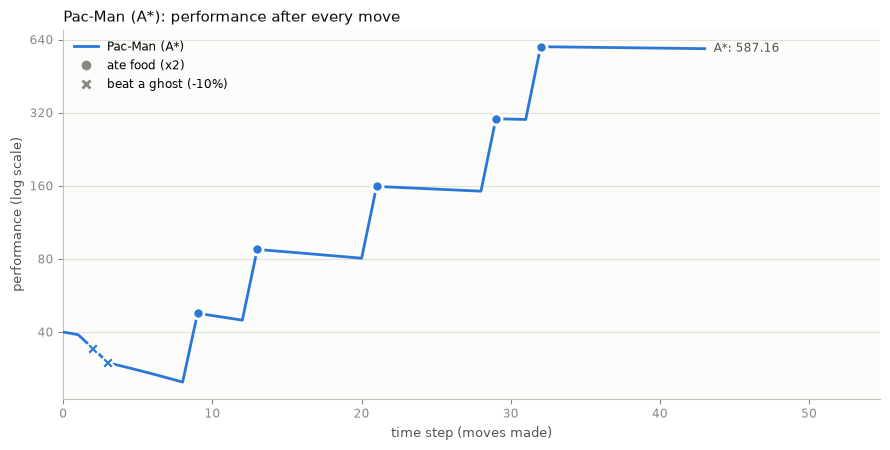

In [19]:
plotPerformance([pac_astar], title="Pac-Man (A*): performance after every move")

Pac-Man meets two ghosts on its very first moves, before it has eaten anything. It wins both fights because its performance is still above their power. Every food dot then doubles its performance, so later ghosts are no threat.

**Can Pac-Man lose?** Yes, if it meets a ghost when its performance is not above the ghost's power. To show that this rule works, here is the same world with a tired Pac-Man that starts at 20 instead of 40:

In [20]:
world_weak = PacmanWorldEnvironment(maze, start, exit_, seed=SEED)
weak = PacmanAgentAstar(start, graph, foods, exit_, SPACE, name='weak Pac-Man', verbose=False)
weak.performance = 20          # normally 40
world_weak.add_thing(weak)
world_weak.run()

t=  0 | weak Pac-Man starts at (7, 1) with performance 20
t=  2 | met a ghost (power 26) at (7, 3) with performance 18 and was KILLED
== weak Pac-Man was killed after 2 steps, final performance 18


Under the real rules this is very unlikely. Pac-Man starts at 40, above the strongest possible ghost (30), and it would need about 10 moves without eating to drop to 30 or below. Since it always heads for the nearest food, that is rare. The test below runs 300 random worlds:

In [21]:
outcomes = {'reached the exit': 0, 'killed by a ghost': 0}
fights, final_perf = 0, []
for k in range(300):
    m_, s_, e_, f_ = makePacmanMaze(10, seed=k)
    g_ = buildPacmanGraph(m_)
    w_ = PacmanWorldEnvironment(m_, s_, e_, seed=k, verbose=False)
    p_ = PacmanAgentAstar(s_, g_, f_, e_, SPACE, verbose=False)
    w_.add_thing(p_); w_.run()
    outcomes['reached the exit' if p_.done else 'killed by a ghost'] += 1
    fights += sum(ev[1] in ('won', 'killed') for ev in p_.events)
    final_perf.append(p_.performance)
print(outcomes)
print(f"average number of ghost fights per run: {fights / 300:.2f}")
print(f"average final performance: {np.mean(final_perf):.1f}")

{'reached the exit': 300, 'killed by a ghost': 0}
average number of ghost fights per run: 1.29
average final performance: 865.3


## Task 7 — Iterative-Deepening A* (IDA*)

**Idea:** a depth-first search that is not allowed to go past an **f-cost limit**. If it finds no goal inside the limit, the limit is raised to the smallest f-value that was cut off, and the search starts again from the root. Each pass explores one "contour" of f-values. A\* keeps a frontier and a table of reached states; IDA\* stores **only the current path**.

| Pseudocode | `IDA_StarSearchAgentProgram` |
|---|---|
| `root ← MAKE-NODE(INITIAL-STATE)` | `root = Node(problem.initial)` |
| `f-limit ← f-COST(root)` | `f_limit = fcost(root)` |
| `solution, f-limit ← DFS-CONTOUR(root, f-limit)` | `solution, f_limit = dfs_contour(root, f_limit)` |
| `if f-COST[node] > f-limit: return null, f-COST[node]` | `if f_node > f_limit: return None, f_node` |
| `if GOAL-TEST: return node, f-limit` | `if problem.goal_test(...): return node, f_limit` |
| `next-f ← MIN(next-f, new-f)` | `next_f = min(next_f, new_f)` |
| `if f-limit = ∞: return failure` | `if f_limit[0] == math.inf: return None` |

Two practical additions:
1. **Skip cells already on the current path.** Left/right moves cost 0, so going left, right, left, … never increases f, and without this check the search would loop forever.
2. Children are tried in order of their f-value (most promising first).

It is used with the admissible `mazeCostHeuristic`, so it finds the cheapest path, the same cost as A\*. The run below is the first leg of Task 4 (start → the nearest of all food dots) and prints each new f-limit:

In [22]:
ida = IDA_StarSearchAgentProgram(mazeCostHeuristic, verbose=True)
node_ida = ida(MazeProblem(start, list(foods), graph))         # goal = the list of all food dots

astar_mc = A_StarSearchAgentProgram(mazeCostHeuristic, verbose=False)
node_a = astar_mc(MazeProblem(start, list(foods), graph))

IDA* iteration 1: f-limit = 0
IDA* iteration 2: f-limit = 3
[IDA* | h=mazeCostHeuristic] goal (7, 8) reached | nodes expanded: 23 | path cost: 3 | steps: 9 | iterations: 2
[A* | h=mazeCostHeuristic] goal (7, 8) reached | nodes expanded: 19 | path cost: 3 | steps: 9


How to read it: at the start h = 0, because food dot (7, 8) is on the same row and sideways moves are free, so the first f-limit is 0. No food can be reached for cost 0, and the smallest f that was cut off is 3, so the second pass uses f-limit 3 and finds (7, 8). Only two passes are needed because the heuristic is close to the true cost. A weaker heuristic would need many more contours.

### IDA* applied to Tasks 4–5
The same `PacmanAgent` (rational order, the same heuristic) with IDA\* as its search program, run in the same world with the same ghosts:

Pac-Man (IDA*) route plan (rational):
  leg 1: (7, 1) -> (7, 8) (food) | cost 3 | steps 9 | nodes expanded 23
  leg 2: (7, 8) -> (4, 1) (food) | cost 6 | steps 10 | nodes expanded 12
  leg 3: (4, 1) -> (4, 9) (food) | cost 0 | steps 8 | nodes expanded 9
  leg 4: (4, 9) -> (1, 6) (food) | cost 6 | steps 18 | nodes expanded 27
  leg 5: (1, 6) -> (1, 9) (food) | cost 0 | steps 3 | nodes expanded 4
  leg 6: (1, 9) -> (3, 0) (exit) | cost 2 | steps 11 | nodes expanded 11
  TOTAL: cost 17 | steps 59 | nodes expanded 86
t=  0 | Pac-Man (IDA*) starts at (7, 1) with performance 40
t=  2 | met a ghost (power 26) at (7, 3) and WON: performance 38 -> 34.2
t=  3 | met a ghost (power 29) at (7, 4) and WON: performance 33.2 -> 29.88
t=  9 | ate food at (7, 8): performance 23.88 -> 47.76
t= 19 | ate food at (4, 1): performance 37.76 -> 75.52
t= 27 | ate food at (4, 9): performance 67.52 -> 135.04
t= 45 | ate food at (1, 6): performance 117.03999999999999 -> 234.08
t= 48 | ate food at (1, 9): performan

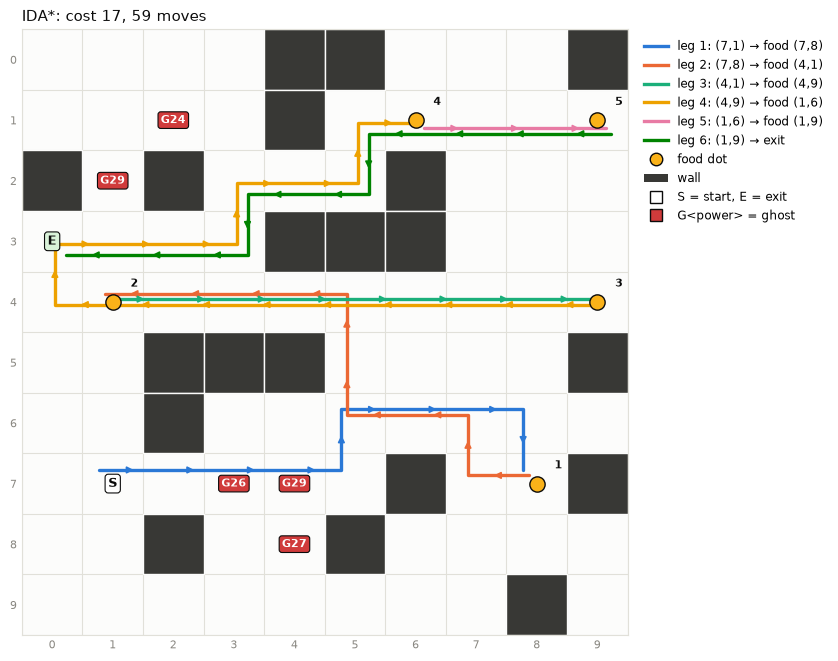

<Axes: title={'left': 'IDA*: cost 17, 59 moves'}>

In [23]:
world_ida = PacmanWorldEnvironment(maze, start, exit_, seed=SEED)
pac_ida = PacmanAgentIDAstar(start, graph, foods, exit_, SPACE)
world_ida.add_thing(pac_ida)
world_ida.run()
drawPacmanWorld(maze, start, exit_, foods, ghosts=world.ghosts, segments=pac_ida.segments,
                food_order=pac_ida.food_order,
                title=f"IDA*: cost {pac_ida.total_cost}, {pac_ida.total_steps} moves")

## Task 8 — Recursive Best-First Search (RBFS)

**Idea:** RBFS behaves like best-first search (always go to the child with the lowest f) but uses only linear memory.
While going down a path it remembers the **best alternative** f-value higher up (`alternative`). When the current path's f grows above that alternative, it **gives up the path** and returns. Before returning, it stores the best f-value found under the abandoned path (the *backed-up value*, `best.f`). That way it knows how good the forgotten subtree was and can come back to it later.

| Pseudocode | `RBFSAgentProgram` |
|---|---|
| `if IS-GOAL(node): return node` | `if problem.goal_test(node.state): return node, node.f` |
| `if successors is empty: return failure, ∞` | `if not successors: return None, INF` |
| `s.f ← max(s.PATH-COST + h(s), node.f)` | `s.f = max(fcost(s), node.f)` |
| `if best.f > f_limit: return failure, best.f` | `if ... best.f > f_limit: ... None, best.f` |
| `alternative ← second-lowest f` | `alternative = successors[1].f` |
| `result, best.f ← RBFS(problem, best, min(f_limit, alternative))` | `result, best.f = rbfs(best, min(f_limit, alternative))` |

As in IDA\*, cells already on the current path are skipped. The same first leg of Task 4, with the trace:

In [24]:
rbfs_trace = RBFSAgentProgram(mazeCostHeuristic, verbose=True)
node_r = rbfs_trace(MazeProblem(start, list(foods), graph))

RBFS: go to (7, 0) (f=0), limit=0
RBFS: go to (7, 2) (f=0), limit=3
RBFS: go to (7, 3) (f=0), limit=3
RBFS: go to (7, 4) (f=0), limit=3
RBFS: go to (7, 5) (f=0), limit=3
RBFS: go to (6, 5) (f=3), limit=3
RBFS: go to (6, 4) (f=3), limit=3
RBFS: go to (6, 3) (f=3), limit=3
RBFS: go to (6, 6) (f=3), limit=3
RBFS: go to (6, 7) (f=3), limit=3
RBFS: go to (6, 8) (f=3), limit=3
RBFS: go to (6, 9) (f=3), limit=3
RBFS: go to (7, 8) (f=3), limit=3
[RBFS | h=mazeCostHeuristic] goal (7, 8) reached | nodes expanded: 13 | path cost: 3 | steps: 9


How to read it:
* RBFS first tries (7, 0) (f = 0), but every path below it has a larger f, so it gives up that branch and stores its backed-up value (3).
* It continues with (7, 2), now with `limit = 3`: the f of the best alternative it just remembered.
* Later it walks into (6, 4) → (6, 3), which is a dead end. It unwinds and **switches** to (6, 6), and from there it reaches the food at (7, 8).

### RBFS applied to Tasks 4–5

Pac-Man (RBFS) route plan (rational):
  leg 1: (7, 1) -> (7, 8) (food) | cost 3 | steps 9 | nodes expanded 13
  leg 2: (7, 8) -> (4, 1) (food) | cost 6 | steps 10 | nodes expanded 12
  leg 3: (4, 1) -> (4, 9) (food) | cost 0 | steps 8 | nodes expanded 9
  leg 4: (4, 9) -> (1, 6) (food) | cost 6 | steps 18 | nodes expanded 27
  leg 5: (1, 6) -> (1, 9) (food) | cost 0 | steps 3 | nodes expanded 4
  leg 6: (1, 9) -> (3, 0) (exit) | cost 2 | steps 11 | nodes expanded 11
  TOTAL: cost 17 | steps 59 | nodes expanded 76
t=  0 | Pac-Man (RBFS) starts at (7, 1) with performance 40
t=  2 | met a ghost (power 26) at (7, 3) and WON: performance 38 -> 34.2
t=  3 | met a ghost (power 29) at (7, 4) and WON: performance 33.2 -> 29.88
t=  9 | ate food at (7, 8): performance 23.88 -> 47.76
t= 19 | ate food at (4, 1): performance 37.76 -> 75.52
t= 27 | ate food at (4, 9): performance 67.52 -> 135.04
t= 45 | ate food at (1, 6): performance 117.03999999999999 -> 234.08
t= 48 | ate food at (1, 9): performan

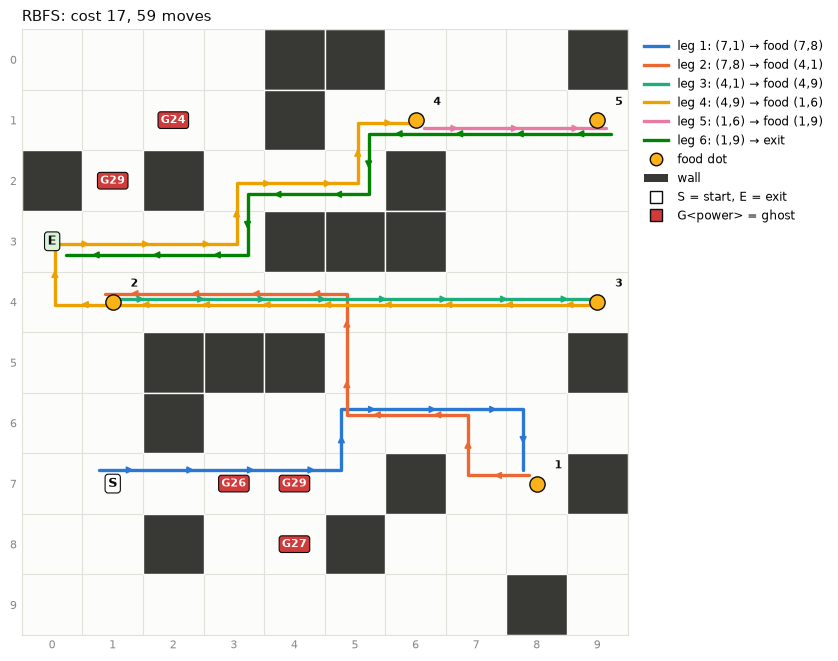

<Axes: title={'left': 'RBFS: cost 17, 59 moves'}>

In [25]:
world_rbfs = PacmanWorldEnvironment(maze, start, exit_, seed=SEED)
pac_rbfs = PacmanAgentRBFS(start, graph, foods, exit_, SPACE)
world_rbfs.add_thing(pac_rbfs)
world_rbfs.run()
drawPacmanWorld(maze, start, exit_, foods, ghosts=world.ghosts, segments=pac_rbfs.segments,
                food_order=pac_rbfs.food_order,
                title=f"RBFS: cost {pac_rbfs.total_cost}, {pac_rbfs.total_steps} moves")

## Comparing A*, IDA* and RBFS (Tasks 4–5 in this world)
*Nodes expanded* and *peak memory* are summed or maximised over the legs of the route. *Peak memory* is the largest number of nodes the search had to keep at once: all reached nodes for A\*, and only the nodes on and next to the current path for IDA\* and RBFS.

In [26]:
def planTime(factory):
    t0 = time.perf_counter()
    ag = factory(start, graph, foods, exit_, SPACE, verbose=False)
    ag(start)
    return time.perf_counter() - t0

rows = []
for ag, factory in [(pac_astar, PacmanAgentAstar), (pac_ida, PacmanAgentIDAstar), (pac_rbfs, PacmanAgentRBFS)]:
    rows.append({'agent': ag.name,
                 'route cost': ag.total_cost,
                 'moves': ag.total_steps,
                 'nodes expanded': ag.total_expanded,
                 'peak memory (nodes)': max(s['stats']['peak_memory'] for s in ag.segments),
                 'planning time (ms)': round(1000 * planTime(factory), 1),
                 'outcome': 'reached the exit' if ag.done else 'killed',
                 'final performance': ag.performance})
pd.DataFrame(rows).set_index('agent')

,route cost,moves,nodes expanded,peak memory (nodes),planning time (ms),outcome,final performance
agent,,,,,,,
Pac-Man (A*),17,43,69,32,3.5,reached the exit,587.16
Pac-Man (IDA*),17,59,86,38,1.7,reached the exit,451.16
Pac-Man (RBFS),17,59,76,38,1.7,reached the exit,451.16


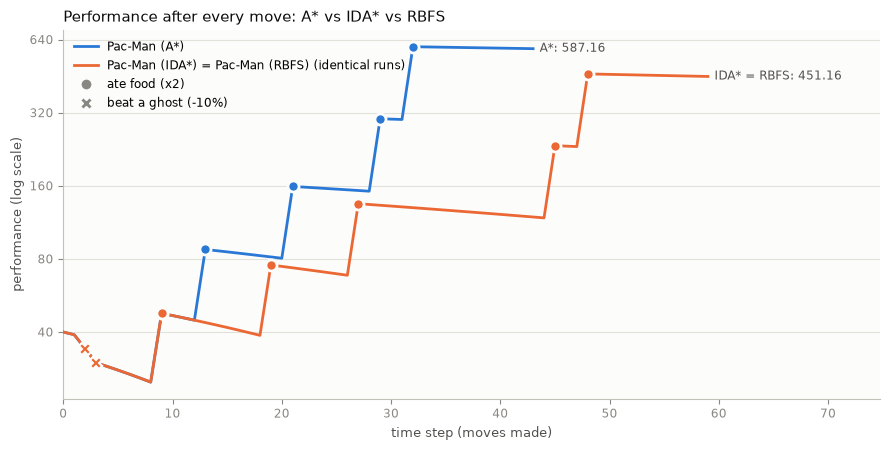

In [27]:
plotPerformance([pac_astar, pac_ida, pac_rbfs], title="Performance after every move: A* vs IDA* vs RBFS")

**What the comparison shows**
* **All three find a route with the same cost (17).** With an admissible heuristic every leg is a cheapest path.
* **A\*'s route has 16 fewer moves (43 vs 59), so Pac-Man ends with more performance (587 vs 451).** There are two reasons. At (7, 8) two food dots are equally cheap (cost 6), and IDA\*/RBFS picked the other one. Also, the textbook IDA\*/RBFS don't mind extra *free* sideways moves (their leg 4 takes 18 moves instead of 8), while A\*'s tie-break avoids them.
* **Memory.** In theory A\* stores every node it reaches (in the worst case exponential in the depth), while IDA\* and RBFS store only the current path and its siblings (about b·d nodes). In a 10 × 10 maze the whole world is only about 80 cells and a good heuristic keeps A\* focused, so all three need just a few dozen nodes. The memory advantage of IDA\*/RBFS matters for huge state spaces, such as the 15-puzzle with about 10¹³ states, where A\* runs out of memory.
* **Speed:** in this world all three plan the whole route in a few milliseconds.

### A hard case for IDA* and RBFS
Free sideways moves make many paths cost exactly the same, and IDA\* and RBFS cannot remember which cells they have already explored. On some problems that means a huge amount of repeated work. This is the worst problem found in testing (another world, a cheapest path of 30 moves with a long detour):

In [28]:
m12, s12, e12, f12 = makePacmanMaze(10, seed=12)
g12 = buildPacmanGraph(m12)
hard = MazeProblem((2, 1), (7, 0), g12)
rows = []
for name, P in [('A*', A_StarSearchAgentProgram), ('IDA*', IDA_StarSearchAgentProgram), ('RBFS', RBFSAgentProgram)]:
    prog = P(mazeCostHeuristic, verbose=False, report=False)
    t0 = time.perf_counter()
    nd = prog(hard)
    rows.append({'algorithm': name, 'path cost': nd.path_cost, 'nodes expanded': prog.stats['nodes_expanded'],
                 'peak memory (nodes)': prog.stats['peak_memory'],
                 'time (s)': round(time.perf_counter() - t0, 2)})
pd.DataFrame(rows).set_index('algorithm')

,path cost,nodes expanded,peak memory (nodes),time (s)
algorithm,,,,
A*,11,65,73,0.00
IDA*,11,127671,76,1.82
RBFS,11,887938,80,13.48


IDA\* needs only 3 contours here (f-limit 5, 8, 11), but inside each contour it walks through a huge number of equally cheap paths, because sideways moves are free and it has no memory of visited cells. RBFS is even worse: it keeps abandoning and re-expanding the same subtrees. A\* remembers every reached cell and expands just 65 nodes.

## Summary — the main points to explain

1. **A\* evaluates f(n) = g(n) + h(n).** It is optimal only if h never overestimates. In this maze left/right moves are free, so **Euclidean and Manhattan can overestimate**. **Manhattan is faster** (fewer expansions) but, like Euclidean, it occasionally returns a more expensive path (Tasks 1–2).
2. **The heuristic designed for this maze** counts only the vertical moves that are unavoidable: 2 per row up, 1 per row down. It never overestimates, so A\* always finds the cheapest path. With a *list* of food dots as the goal, h = distance to the nearest food, and the first food A\* reaches is the cheapest one to reach. That is the rational choice asked for in Task 4.
3. **Cheapest food first** is roughly 20–25 % cheaper than visiting the food in listed order, and finds the best order in about 60 % of the worlds. It is greedy (no look-ahead), so it is not always optimal.
4. **The world (Tasks 3, 5, 6):** ghosts are hidden `Thing`s that the agent only notices in its own cell. Performance starts at 40, food doubles it, and a fight is won only if performance > power, at a cost of 10 %. With these numbers Pac-Man almost never dies: it starts above the strongest ghost and food doubles its performance quickly.
5. **IDA\* and RBFS (Tasks 7–8)** find routes with the same cost as A\*, while storing only the current path. That matters for huge state spaces; in this small maze all three need a few dozen nodes. The price is **repeated work**. IDA\* re-explores everything on each new f-limit; RBFS re-expands a subtree whenever it switches back to it. Free moves (cost 0) make this especially bad, as the hard case shows. Their routes can also contain extra free sideways moves, which cost Pac-Man performance; A\*'s tie-break avoids them.